In [1]:
import os
import sys
import glob
import gc

import numpy as np
from sklearn import linear_model
import scipy.sparse as sp

import fa2

import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "notebook"  # or "notebook_connected"

import anndata as ad
import scanpy as sc
import pegasus as pg
from pegasusio import UnimodalData

import wot
from wot import ot

import palantir

%matplotlib inline

In [2]:
## Import Organoid Data ##

ORGANOIDS_PATH_REFINED = '/home/deepak/datasets/developing_hippocampus/roussos_organoid_snrnaseq/neocortical_refined/'
organoids_filename = 'neocortical_organoids_subclass_breakdown_subtype_breakdown_annot.h5ad'
organoids_purified = sc.read_h5ad(os.path.join(ORGANOIDS_PATH_REFINED, organoids_filename))

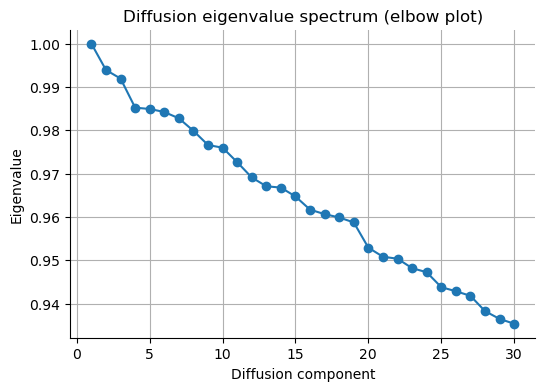

In [3]:
# Identify Number of Diffusion Components #

dm_res = palantir.utils.run_diffusion_maps(organoids_purified, n_components=30)

eigvals = dm_res['EigenValues']

# Plot elbow curve
plt.figure(figsize=(6,4))
plt.plot(range(1, len(eigvals)+1), eigvals, 'o-', markersize=6)
plt.xlabel("Diffusion component")
plt.ylabel("Eigenvalue")
plt.title("Diffusion eigenvalue spectrum (elbow plot)")
plt.grid(True)
plt.show()

In [4]:
## Set Diffusion Component Number at 7 ##

dm_res = palantir.utils.run_diffusion_maps(organoids_purified, n_components=9)

In [5]:
## Recalculate Neighbors For Usable Connectivity Graph ##

sc.pp.neighbors(organoids_purified, use_rep='X_pca_regressed_harmony', n_neighbors=15)

sc.tl.draw_graph(organoids_purified, layout='fa', key_added_ext='ForceAtlas')

In [6]:
## MAGIC Imputation ##

imputed_X = palantir.utils.run_magic_imputation(organoids_purified)

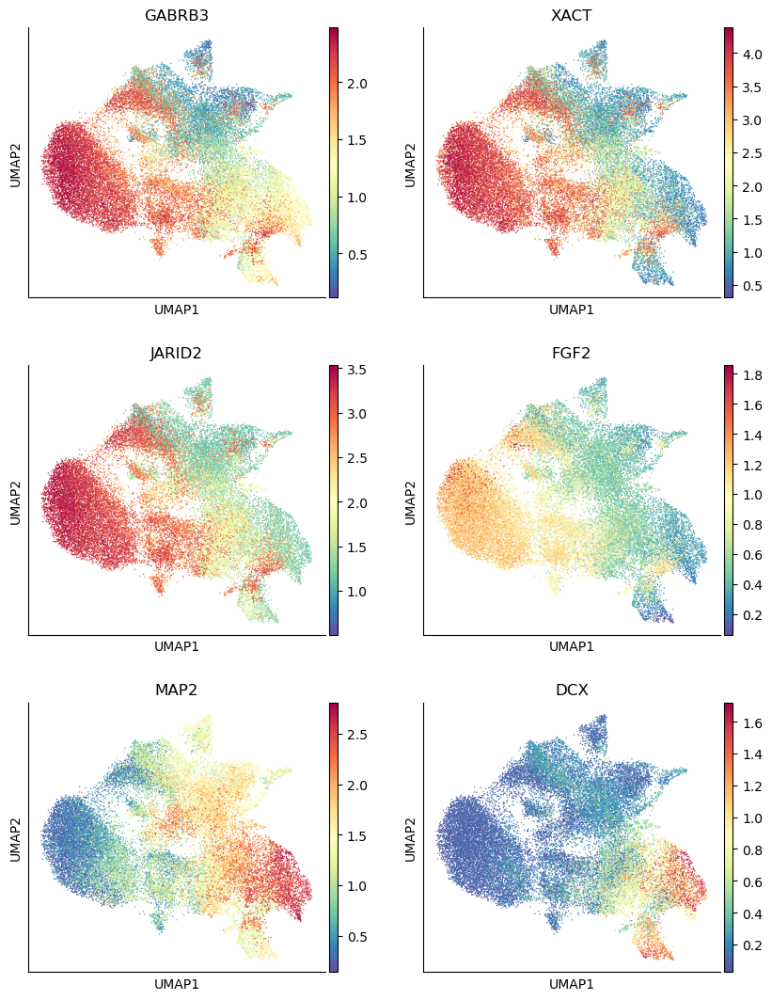

In [7]:
## Key Genes On UMAP ##

sc.pl.embedding(organoids_purified, basis="umap", layer="MAGIC_imputed_data", 
                ncols=2, color=["GABRB3", "XACT", "JARID2", "FGF2", "MAP2", "DCX"])
plt.show()

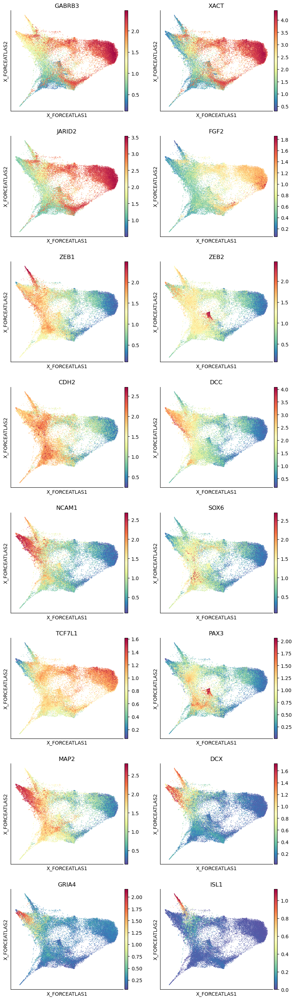

In [8]:
## Key Genes On Force Directed Layout ##

sc.pl.embedding(organoids_purified, basis="X_draw_graph_ForceAtlas", layer="MAGIC_imputed_data", 
                ncols=2, color=["GABRB3", "XACT", "JARID2", "FGF2", "ZEB1", "ZEB2", "CDH2", "DCC", "NCAM1", "SOX6",
                                "TCF7L1", "PAX3", "MAP2", "DCX", "GRIA4", "ISL1"])
plt.show()

In [9]:
organoids_purified.obs.columns

Index(['n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts',
       'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes',
       'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',
       'pct_counts_in_top_500_genes', 'total_counts_mito',
       'log1p_total_counts_mito', 'pct_counts_mito', 'QC_pass', 'batch',
       'SubID_vs', 'gt_pass', 'Donor_ID', 'barcodes', 'set', 'Donor',
       'Condition', 'Day', 'Donor-Condition-Timepoint', 'n_counts',
       'percent_mito', 'Sex', 'G1/S', 'G2/M', 'cycle_diff', 'cycling',
       'predicted_phase', 'class', 'subclass', 'subtype', 'doublet_score',
       'pred_dbl', 'demux_type', 'braun_cellclass_pred', 'braun_tissue_pred',
       'sestan_full_pred', 'sestan_balanced_hipp_pred',
       'sestan_neocortex_pred', 'hnoca_celltype_pred', 'shendure_organ_pred',
       'shendure_organ_cell_pred', 'subtype_annot_markers', 'subtype_annot',
       'subclass_annot_markers', 'subclass_annot', 'class_subclass',
       'class_su

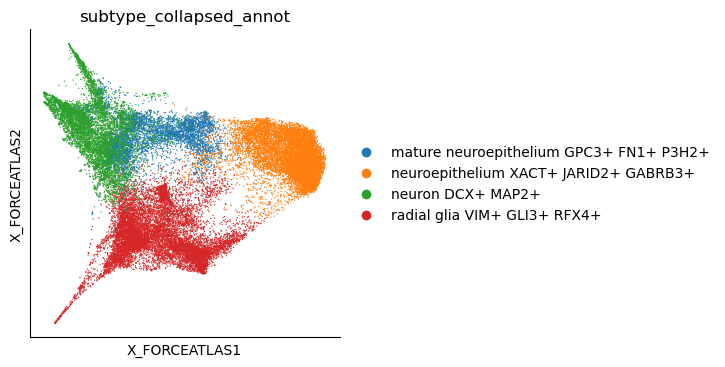

In [10]:
sc.pl.embedding(organoids_purified, basis="X_draw_graph_ForceAtlas", color='subtype_collapsed_annot')

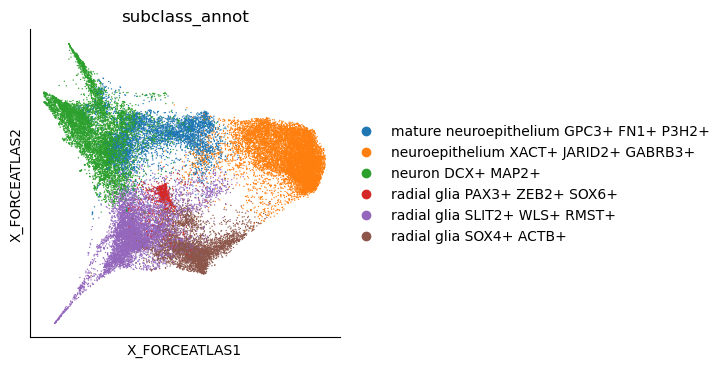

In [11]:
sc.pl.embedding(organoids_purified, basis="X_draw_graph_ForceAtlas", color='subclass_annot')

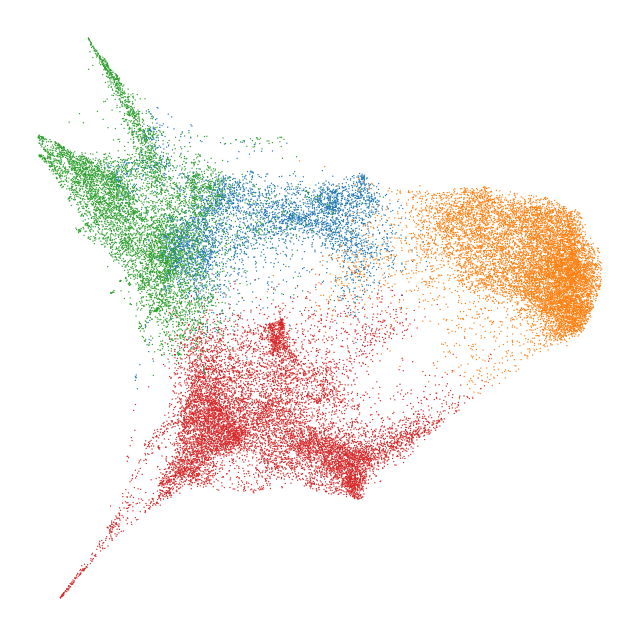

In [12]:
# Create the figure and axis
fig, ax = plt.subplots(figsize=(8, 8))  # Adjust the size here

# Plot the embedding with customized settings
sc.pl.embedding(organoids_purified, 
                basis="X_draw_graph_ForceAtlas", 
                color='subtype_collapsed_annot', 
                ax=ax,  # Use the created axis for plotting
                show=False,  # Don't show yet, to adjust further
                legend_loc=None,  # Remove legend
                title='',  # Remove title
                )

# Remove axis lines and ticks
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.tick_params(axis='both', which='both', length=0)  # Remove ticks
ax.set_xlabel('')  # Remove x-label
ax.set_ylabel('')  # Remove y-label

# Optionally save the figure
plt.savefig('/home/deepak/repositories/hippocampus/panels/force_directed_subtype_collapsed_annot.png', format='png')  

# Show the plot
plt.show()

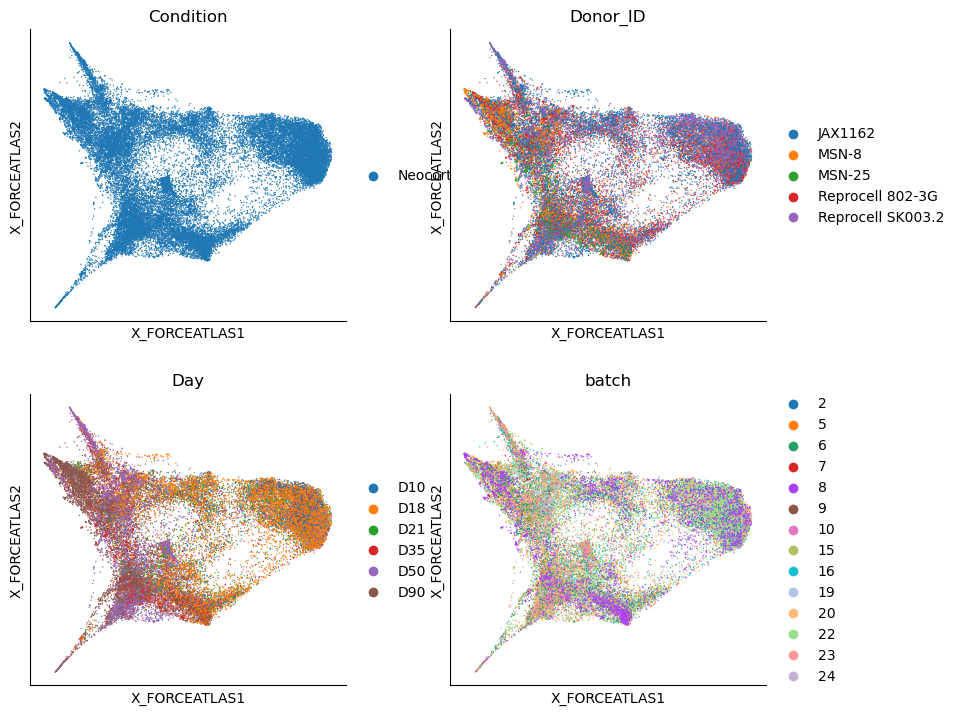

In [13]:
sc.pl.embedding(organoids_purified, basis="X_draw_graph_ForceAtlas", layer="MAGIC_imputed_data", 
                ncols=2, color=["Condition", "Donor_ID", "Day", "batch"])
plt.show()

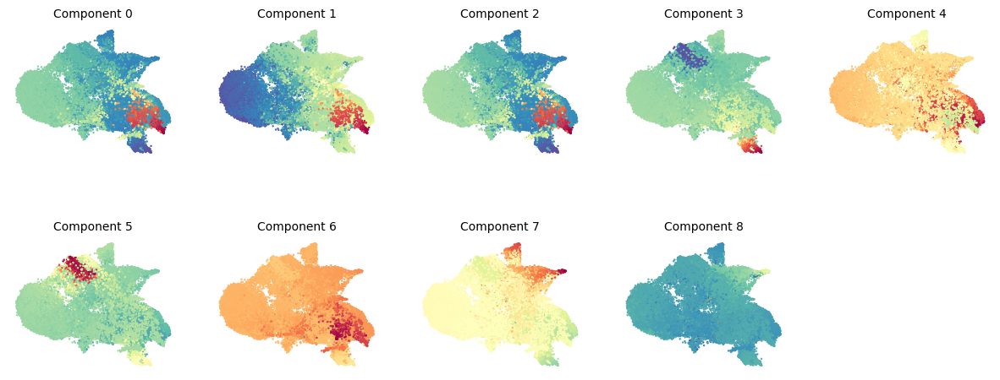

In [14]:
# Show Diffusion Plots ##

palantir.plot.plot_diffusion_components(organoids_purified)
plt.show()

In [15]:
## All 4 States Are Prevalent At D90 ##

organoids_purified[organoids_purified.obs['Day'] == 'D90'].obs['class_subclass'].value_counts() / organoids_purified.obs['class_subclass'].value_counts()

class_subclass
1_1    0.301226
1_2    0.226627
1_3    0.097222
2_1    0.434863
2_2    0.135058
3_1    0.273200
3_2    0.188885
Name: count, dtype: float64

In [16]:
organoids_purified.obs.columns

Index(['n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts',
       'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes',
       'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',
       'pct_counts_in_top_500_genes', 'total_counts_mito',
       'log1p_total_counts_mito', 'pct_counts_mito', 'QC_pass', 'batch',
       'SubID_vs', 'gt_pass', 'Donor_ID', 'barcodes', 'set', 'Donor',
       'Condition', 'Day', 'Donor-Condition-Timepoint', 'n_counts',
       'percent_mito', 'Sex', 'G1/S', 'G2/M', 'cycle_diff', 'cycling',
       'predicted_phase', 'class', 'subclass', 'subtype', 'doublet_score',
       'pred_dbl', 'demux_type', 'braun_cellclass_pred', 'braun_tissue_pred',
       'sestan_full_pred', 'sestan_balanced_hipp_pred',
       'sestan_neocortex_pred', 'hnoca_celltype_pred', 'shendure_organ_pred',
       'shendure_organ_cell_pred', 'subtype_annot_markers', 'subtype_annot',
       'subclass_annot_markers', 'subclass_annot', 'class_subclass',
       'class_su

In [17]:
organoids_purified.obs['subtype_collapsed_annot_no_markers'].value_counts()

subtype_collapsed_annot_no_markers
radial_glia               11417
neuroepithelium            9657
neuron                     6993
mature_neuroepithelium     4213
Name: count, dtype: int64

In [19]:
## Calculate Terminal Points ##

terminals_dict = {}

for cluster in organoids_purified.obs['subtype_collapsed_annot_no_markers'].value_counts().index:
    
    d90_mask = organoids_purified.obs['Day'] == 'D90'
    
    d90_coords = organoids_purified.obsm['X_draw_graph_ForceAtlas'][d90_mask]
    
    # Step 3: (Optional) Filter D90 further by subclass_annot (e.g., '1-1s')
    subclass_mask = (organoids_purified.obs['subtype_collapsed_annot_no_markers'] == cluster)
    d90_subclass_mask = d90_mask & subclass_mask
    d90_cluster_coords = organoids_purified.obsm['X_draw_graph_ForceAtlas'][d90_subclass_mask]
    d90_cluster_centroid = d90_cluster_coords.mean(axis=0)
    
    # Step 4: Compute distances from D90 cells to the centroid
    distances = np.linalg.norm(d90_cluster_coords - d90_cluster_centroid, axis=1)
    
    # Step 5: Find index of the closest point (within D90 cells)
    closest_idx_within_d90 = np.argmin(distances)
     
    # Get the original index of the closest D90 point to the centroid
    d90_subclass_indices = np.where(d90_subclass_mask)[0]
    closest_index = d90_subclass_indices[closest_idx_within_d90]
    
    # (Optional) Get the actual index label if needed
    closest_index_label = organoids_purified.obs_names[closest_index]

    terminals_dict[cluster] = closest_index_label

## Get Starting Index ##

starting_mask = (organoids_purified.obs['Day'] == 'D10') & (organoids_purified.obs['subtype_collapsed_annot_no_markers'] == 'neuroepithelium')

starting_coords = organoids_purified.obsm['X_draw_graph_ForceAtlas'][starting_mask]

starting_centroid = starting_coords.mean(axis=0)

# Step 4: Compute distances from D90 cells to the centroid
starting_distances = np.linalg.norm(starting_coords - starting_centroid, axis=1)

# Step 5: Find index of the closest point (within D90 cells)
closest_idx_within_d10 = np.argmin(starting_distances)

# Get the original index of the closest D10 point to the centroid
d10_neuroepithelium_indices = np.where(starting_mask)[0]

closest_index = d10_neuroepithelium_indices[closest_idx_within_d10]

# Get the actual index label if needed
starting_label = organoids_purified.obs_names[closest_index]

In [20]:
## Set Terminal States and Visualize ##

organoids_purified.obs['terminal_states'] = organoids_purified.obs['subtype_collapsed_annot_no_markers']
organoids_purified.obs['terminal_states'] = organoids_purified.obs['terminal_states'].astype('str')
organoids_purified.obs.loc[(organoids_purified.obs_names.isin(terminals_dict.values())), 'terminal_states'] = 'terminal_state'

organoids_purified.obs.loc[starting_label, 'terminal_states'] = 'starting_state'

In [21]:
organoids_purified.obs['terminal_states'].value_counts()

terminal_states
radial_glia               11416
neuroepithelium            9655
neuron                     6992
mature_neuroepithelium     4212
terminal_state                4
starting_state                1
Name: count, dtype: int64

In [22]:
organoids_purified.uns['terminal_states_colors'] = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#bf812d']

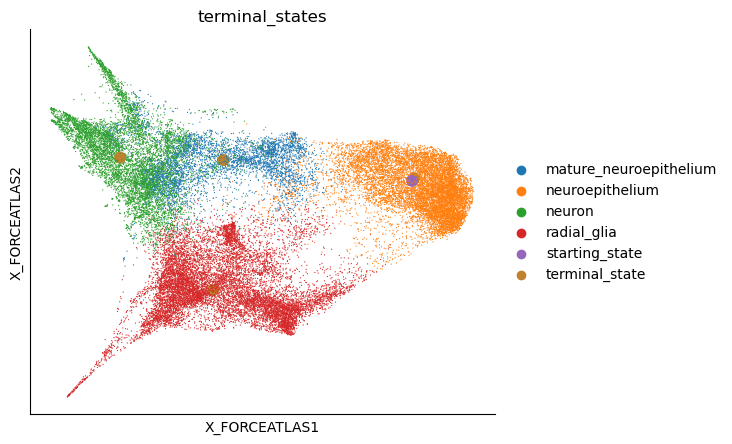

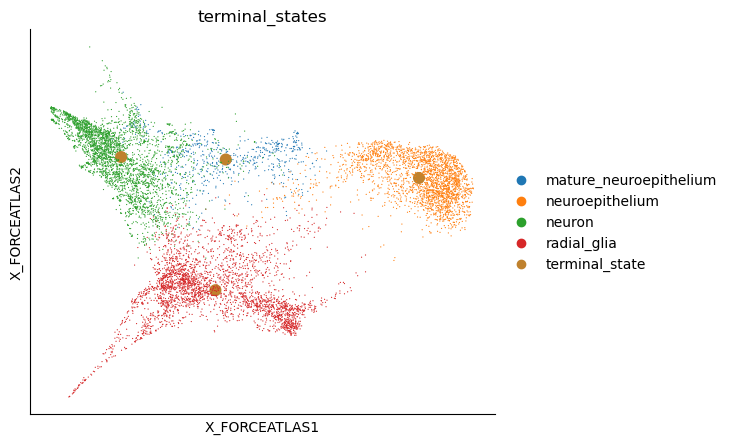

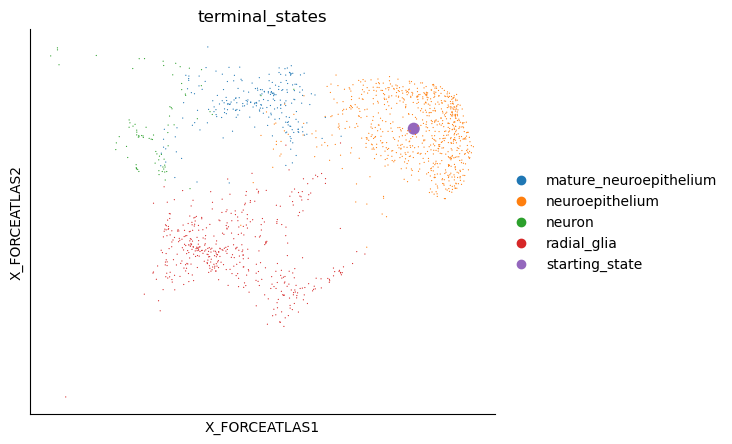

In [23]:
## Visualize Terminal States ##

terminal_mask = organoids_purified.obs_names.isin(terminals_dict.values())
non_terminal_mask = ~terminal_mask

organoids_purified.obs['terminal_states_sizes'] = organoids_purified.obs['terminal_states'].apply(lambda x:
                                                                                                  300 if ((x == 'terminal_state') 
                                                                                                  or (x == 'starting_state')) else 3)

# Create a figure and axes with the desired size
fig, ax = plt.subplots(figsize=(6, 5))

# Plot using Scanpy, but pass the axes explicitly
sc.pl.embedding(organoids_purified, basis='X_draw_graph_ForceAtlas', color='terminal_states',
                size=organoids_purified.obs['terminal_states_sizes'],  ax=ax, show=False)

plt.show()

# Create a figure and axes with the desired size
fig, ax = plt.subplots(figsize=(6, 5))

# Plot using Scanpy, but pass the axes explicitly
sc.pl.embedding(organoids_purified[organoids_purified.obs['Day'] == 'D90'], basis='X_draw_graph_ForceAtlas', color='terminal_states',
                size=organoids_purified[organoids_purified.obs['Day'] == 'D90'].obs['terminal_states_sizes'],  ax=ax, show=False, zorder=5)

plt.show()

# Create a figure and axes with the desired size
fig, ax = plt.subplots(figsize=(6, 5))

# Plot using Scanpy, but pass the axes explicitly
sc.pl.embedding(organoids_purified[organoids_purified.obs['Day'] == 'D10'], basis='X_draw_graph_ForceAtlas', color='terminal_states',
                size=organoids_purified[organoids_purified.obs['Day'] == 'D10'].obs['terminal_states_sizes'], zorder=5, ax=ax, show=False)

plt.show()

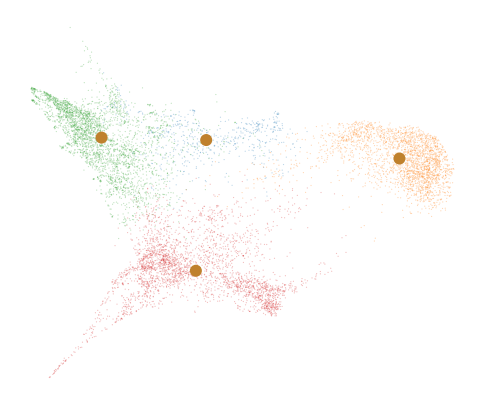

In [24]:
fig, ax = plt.subplots(figsize=(6, 5))

# Plot non-terminal states first (semi-transparent)
sc.pl.embedding(organoids_purified[(organoids_purified.obs['Day'] == 'D90') & (organoids_purified.obs['terminal_states'] != 'terminal_state')],
                basis='X_draw_graph_ForceAtlas', color='terminal_states',
                size=organoids_purified[(organoids_purified.obs['Day'] == 'D90') & (organoids_purified.obs['terminal_states'] != 'terminal_state')].obs['terminal_states_sizes'],
                ax=ax, show=False, alpha=0.3, zorder=1, legend_loc=None)

# Plot terminal states on top with full opacity and higher zorder
sc.pl.embedding(organoids_purified[(organoids_purified.obs['Day'] == 'D90') & (organoids_purified.obs['terminal_states'] == 'terminal_state')],
                basis='X_draw_graph_ForceAtlas', color='terminal_states',
                size=organoids_purified[(organoids_purified.obs['Day'] == 'D90') & (organoids_purified.obs['terminal_states'] == 'terminal_state')].obs['terminal_states_sizes'],
                ax=ax, show=False, alpha=1, zorder=5, legend_loc=None)

# Remove axis lines and ticks
ax.set_title('') 
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.tick_params(axis='both', which='both', length=0)  # Remove ticks
ax.set_xlabel('')  # Remove x-label
ax.set_ylabel('')  # Remove y-label

# Optionally save the figure
plt.savefig('/home/deepak/repositories/hippocampus/panels/d90_terminal_states_force_directed.png', format='png')  

plt.show()

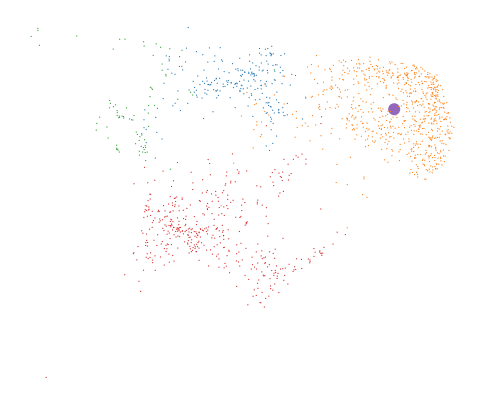

In [25]:
# Create a figure and axes with the desired size
fig, ax = plt.subplots(figsize=(6, 5))

# Plot using Scanpy, but pass the axes explicitly
sc.pl.embedding(organoids_purified[organoids_purified.obs['Day'] == 'D10'], basis='X_draw_graph_ForceAtlas', color='terminal_states',
                size=organoids_purified[organoids_purified.obs['Day'] == 'D10'].obs['terminal_states_sizes'], zorder=5, 
                legend_loc=None, ax=ax, show=False)

# Remove axis lines and ticks
ax.set_title('') 
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.tick_params(axis='both', which='both', length=0)  # Remove ticks
ax.set_xlabel('')  # Remove x-label
ax.set_ylabel('')  # Remove y-label

plt.savefig('/home/deepak/repositories/hippocampus/panels/d10_starting_state_force_directed.png', format='png')  

plt.show()

In [26]:
terminal_states = pd.Series(data=list(terminals_dict.keys()), index=list(terminals_dict.values()))

pr_res = palantir.core.run_palantir(organoids_purified, starting_label, eigvec_key='DM_EigenVectors',
                                    num_waypoints=500, terminal_states=terminal_states)

Sampling and flocking waypoints...
Time for determining waypoints: 0.009623416264851888 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.24346007108688356 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9987
Correlation at iteration 2: 0.9999
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


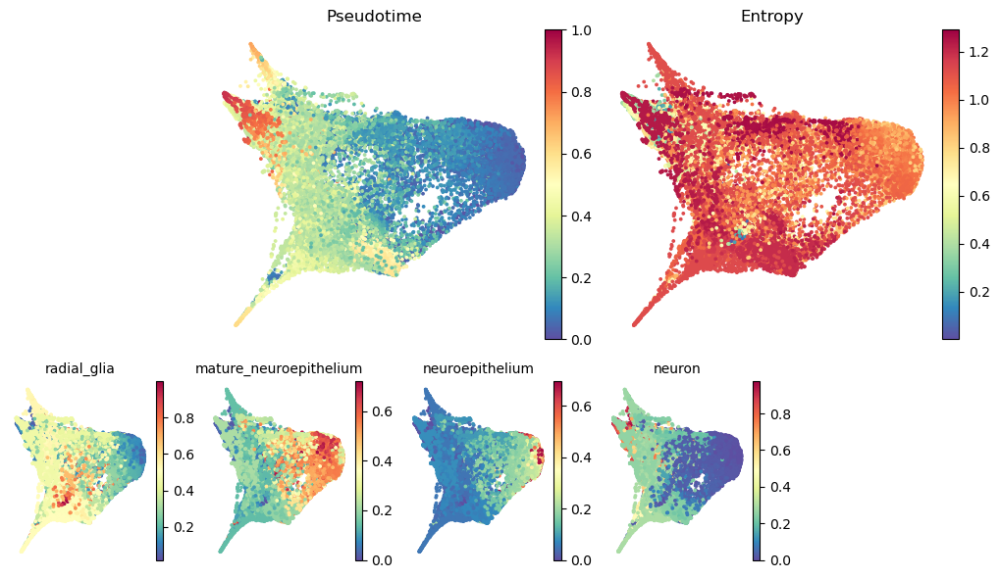

In [27]:
palantir.plot.plot_palantir_results(organoids_purified, s=3, embedding_basis='X_draw_graph_ForceAtlas')
plt.show()

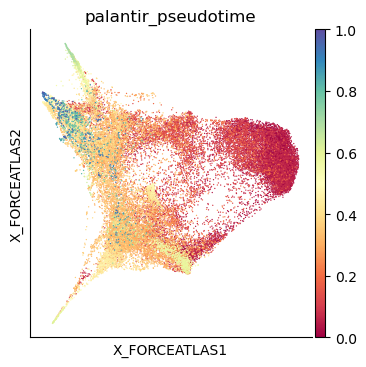

In [28]:
sc.pl.embedding(organoids_purified, basis='X_draw_graph_ForceAtlas', 
                color='palantir_pseudotime', cmap=sns.color_palette("Spectral", as_cmap=True))

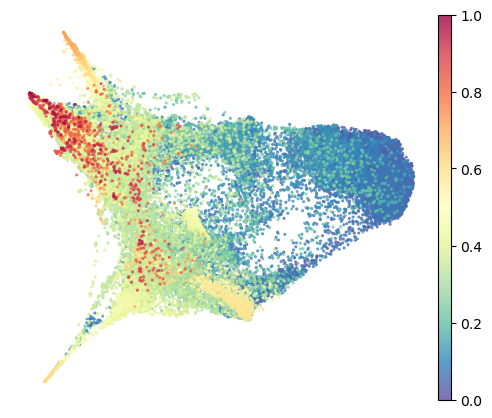

In [29]:
fig, ax = plt.subplots(figsize=(6, 5))

sc.pl.embedding(organoids_purified, basis='X_draw_graph_ForceAtlas', 
                color='palantir_pseudotime', cmap=sns.color_palette("Spectral", as_cmap=True).reversed(), s=20, 
                alpha=0.8, ax=ax, show=False)

# Remove axis lines and ticks
ax.set_title('') 
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.tick_params(axis='both', which='both', length=0)  # Remove ticks
ax.set_xlabel('')  
ax.set_ylabel('')  

plt.savefig('/home/deepak/repositories/hippocampus/panels/pseudotime_force_directed_legend.png', format='png')  
plt.savefig('/home/deepak/repositories/hippocampus/panels/pseudotime_force_directed_legend.svg', format='svg')  
plt.show()

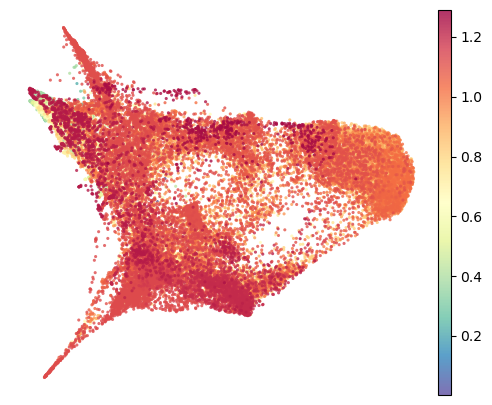

In [30]:
fig, ax = plt.subplots(figsize=(6, 5))

sc.pl.embedding(organoids_purified, basis='X_draw_graph_ForceAtlas', 
                color='palantir_entropy', cmap=sns.color_palette("Spectral", as_cmap=True).reversed(), s=20, 
                alpha=0.8, ax=ax, show=False)

# Remove axis lines and ticks
ax.set_title('') 
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.tick_params(axis='both', which='both', length=0)  # Remove ticks
ax.set_xlabel('')  
ax.set_ylabel('')  

plt.savefig('/home/deepak/repositories/hippocampus/panels/entropy_force_directed_legend.png', format='png')  
plt.savefig('/home/deepak/repositories/hippocampus/panels/entropy_force_directed_legend.svg', format='svg')  
plt.show()

In [31]:
organoids_purified.obs['Day_condensed'] = organoids_purified.obs['Day'].str.replace('D18', 'D20').str.replace('D21', 'D20')

In [32]:
organoids_purified.obs['Day_condensed'] = pd.Categorical(
    organoids_purified.obs['Day_condensed'], 
    categories=['D10', 'D20', 'D35', 'D50', 'D90'], 
    ordered=True)

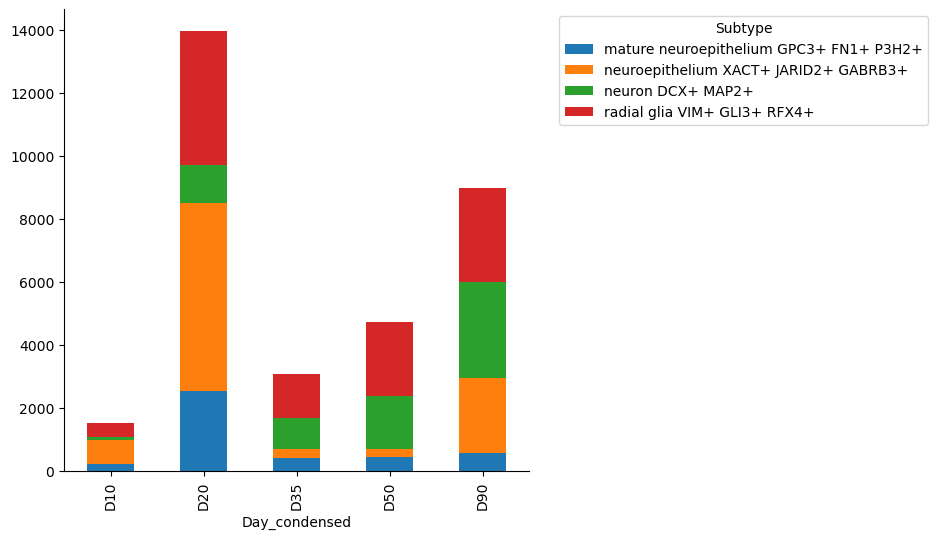

In [177]:
# Get the counts of each subtype for each day
counts = organoids_purified.obs[['Day_condensed', 'subtype_collapsed_annot']].value_counts().unstack(fill_value=0)

colors =  ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# Create the stacked bar plot with custom colors
counts.plot(kind='bar', stacked=True, figsize=(6, 6), color=colors)

# Set the plot labels and title

#plt.xlabel('Day')
#lt.ylabel('Count of Subtypes')
#plt.title('Stacked Bar Plot of Subtypes by Day')
#plt.xticks([''])

# Move the legend outside the plot
plt.legend(title='Subtype', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.savefig('/home/deepak/repositories/hippocampus/panels/stacked_barplot_by_day', format='svg')
plt.show()

<Axes: xlabel='Day_condensed', ylabel='palantir_pseudotime'>

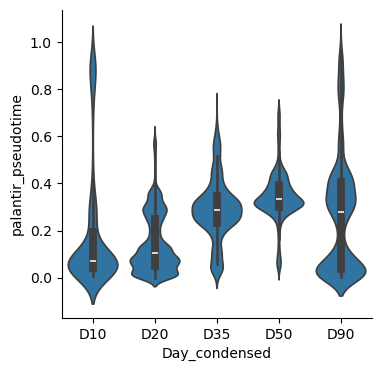

In [33]:
sns.violinplot(organoids_purified.obs, x='Day_condensed', y='palantir_pseudotime', density_norm='width')

In [181]:
organoids_purified.obs['n_genes_by_counts'].mean()

4695.682868649318

/tmp/ipykernel_10992/2128923493.py:7: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




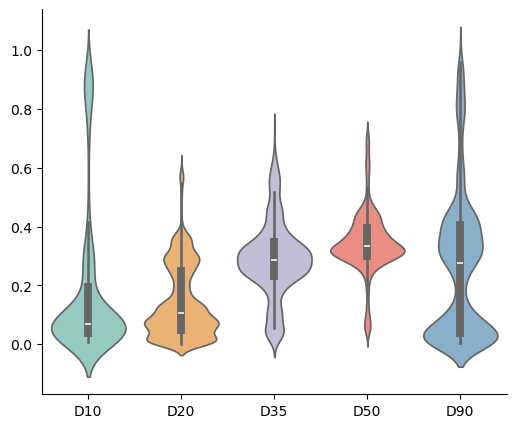

In [175]:
# Define your 6 hex colors
colors = ['#8dd3c7', '#fdb462', '#bebada', '#fb8072', '#80b1d3']  # Example hex colors

fig, ax = plt.subplots(figsize=(6, 5))

# Create the violin plot with a custom color palette
sns.violinplot(data=organoids_purified.obs, x='Day_condensed', y='palantir_pseudotime', palette=colors, 
               density_norm='width', ax=ax)

# Remove axis lines and ticks
ax.set_title('') 
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# ax.spines['left'].set_visible(False)
# ax.spines['bottom'].set_visible(False)

#ax.tick_params(axis='both', which='both', length=0)  # Remove ticks
ax.set_xlabel('')  
ax.set_ylabel('')  

plt.savefig('/home/deepak/repositories/hippocampus/panels/pseudotime_by_day.svg', format='svg')  

# Show the plot
plt.show()

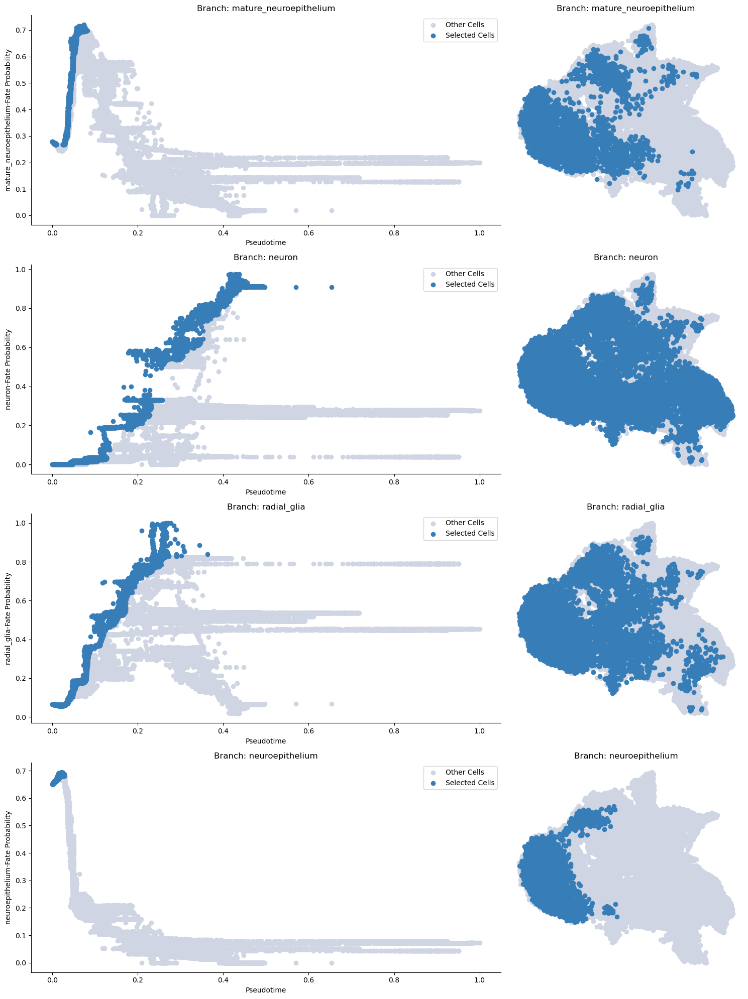

In [35]:
## Observe Branching Probabilities ##

masks = palantir.presults.select_branch_cells(organoids_purified, q=.01, eps=.01)

palantir.plot.plot_branch_selection(organoids_purified)

plt.show()

In [36]:
gene_trends = palantir.presults.compute_gene_trends(organoids_purified, expression_key="MAGIC_imputed_data")

radial_glia
[2025-08-24 17:20:28,505] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (10,458) and rank = 1.0.
[2025-08-24 17:20:28,506] [INFO    ] Using covariance function Matern52(ls=1.0).
[2025-08-24 17:20:29,888] [INFO    ] Sigma interpreted as element-wise standard deviation.
mature_neuroepithelium
[2025-08-24 17:20:32,273] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (3,699) and rank = 1.0.
[2025-08-24 17:20:32,274] [INFO    ] Using covariance function Matern52(ls=1.0).
[2025-08-24 17:20:32,799] [INFO    ] Sigma interpreted as element-wise standard deviation.
neuroepithelium
[2025-08-24 17:20:34,394] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (3,966) and rank = 1.0.
[2025-08-24 17:20:34,395] [INFO    ] Using covariance function Matern52(ls=1.0).
[2025-08-24 17:20:34,838] [INFO    ] Sigma interpreted as element-wise standard deviation.
neuron
[2025-08-24 17:20:38,870] [INFO    ] Using s

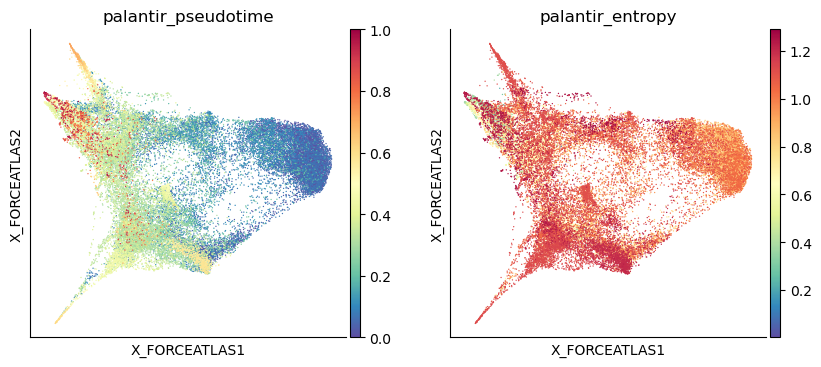

In [37]:
sc.pl.embedding(organoids_purified, basis='X_draw_graph_ForceAtlas', color=['palantir_pseudotime', 'palantir_entropy'], ncols=2)

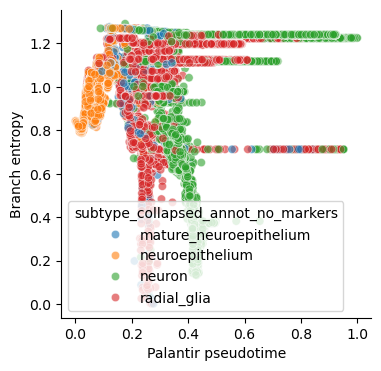

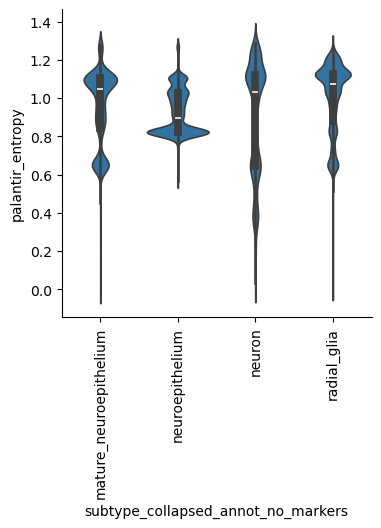

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

# Pseudotime vs entropy
sns.scatterplot(
    x='palantir_pseudotime',
    y='palantir_entropy',
    hue='subtype_collapsed_annot_no_markers',
    data=organoids_purified.obs,
    alpha=0.6
)
plt.xlabel('Palantir pseudotime')
plt.ylabel('Branch entropy')
plt.show()

# Violin plot of entropy per cluster
sns.violinplot(
    x='subtype_collapsed_annot_no_markers',
    y='palantir_entropy',
    data=organoids_purified.obs
)
plt.xticks(rotation=90)
plt.show()


In [39]:
## Examine Trajectories Branching ##

# Palantir branch probabilities
branch_probs = pr_res.branch_probs.copy()

# Optionally, join with cluster or pseudotime info
branch_probs = branch_probs.join(organoids_purified.obs[['subtype_collapsed_annot_no_markers', 'palantir_pseudotime']])

In [40]:
branch_probs['assignment'] = branch_probs[branch_probs.columns[0:4]].idxmax(axis=1)

In [41]:
organoids_purified.obs = organoids_purified.obs.merge(branch_probs[['mature_neuroepithelium', 'neuron', 
                                                                    'radial_glia', 'neuroepithelium']],
                                                                     right_index=True, left_index=True, how='left')

In [42]:
organoids_purified.obs['assignment'] = branch_probs['assignment']

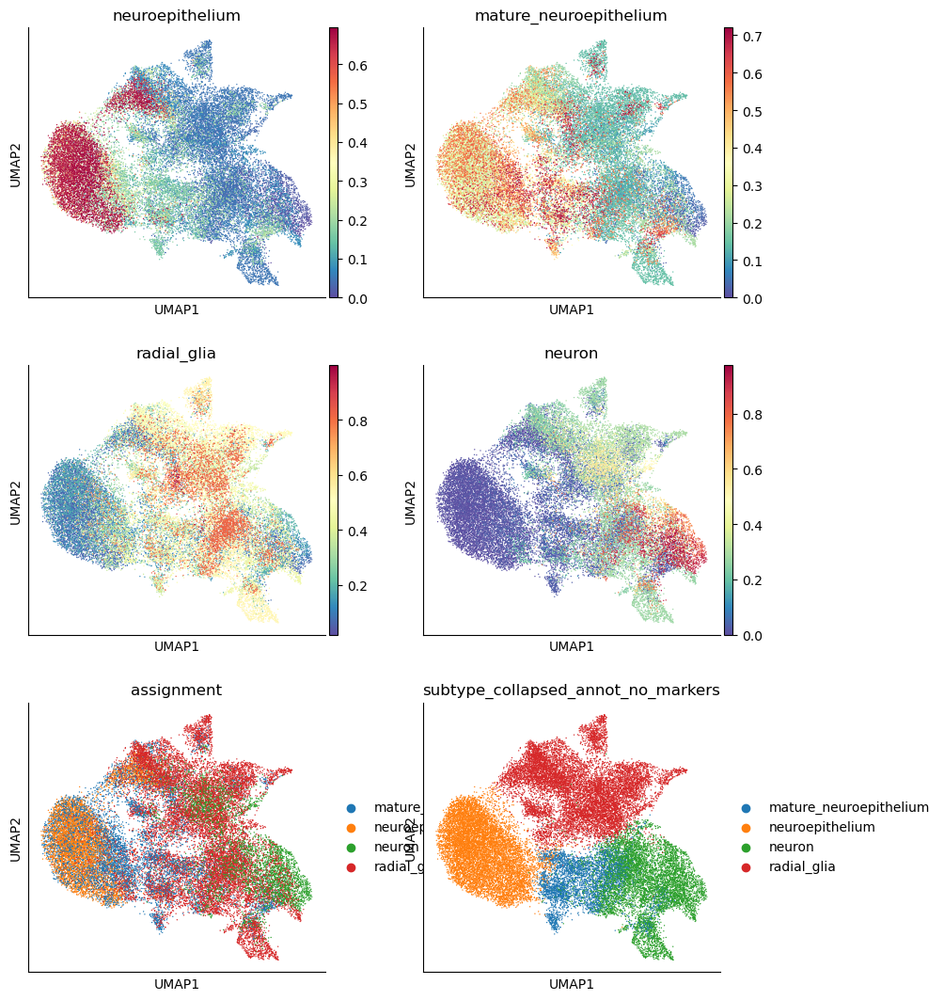

In [43]:
## UMAPs of Individual Trajectories ##

sc.pl.umap(organoids_purified, 
           color=['neuroepithelium', 'mature_neuroepithelium','radial_glia', 'neuron', 'assignment', 
                  'subtype_collapsed_annot_no_markers'], ncols=2)

<Axes: xlabel='palantir_pseudotime', ylabel='None'>

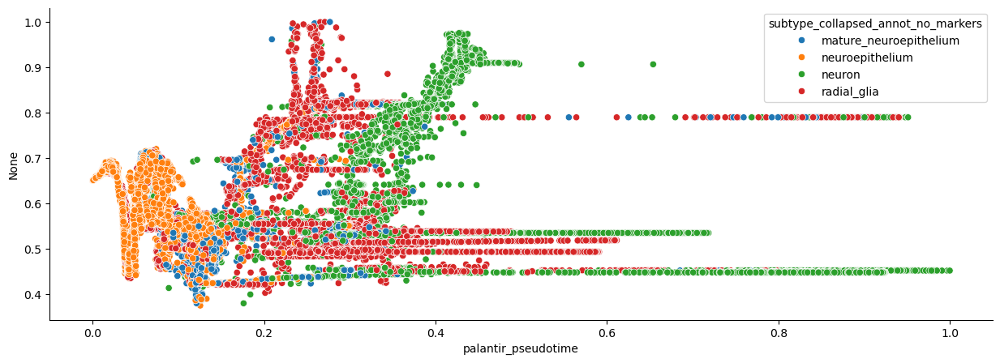

In [44]:
plt.figure(figsize=(15,5))
sns.scatterplot(data=branch_probs, y=branch_probs[branch_probs.columns[0:4]].max(axis=1) , x='palantir_pseudotime', hue='subtype_collapsed_annot_no_markers')

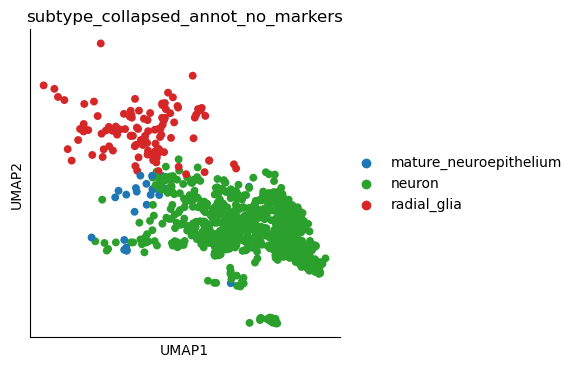

In [45]:
sc.pl.umap(organoids_purified[branch_probs[branch_probs['palantir_pseudotime'] > 0.7].index], 
           color='subtype_collapsed_annot_no_markers')

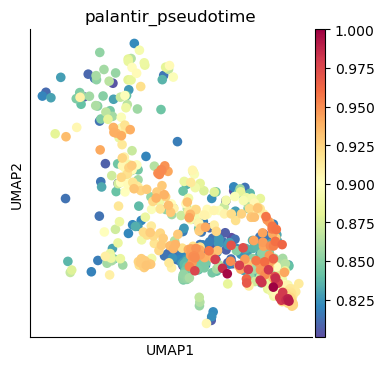

In [46]:
sc.pl.umap(organoids_purified[branch_probs[branch_probs['palantir_pseudotime'] > 0.8].index], color='palantir_pseudotime')

<Axes: xlabel='palantir_pseudotime', ylabel='neuroepithelium'>

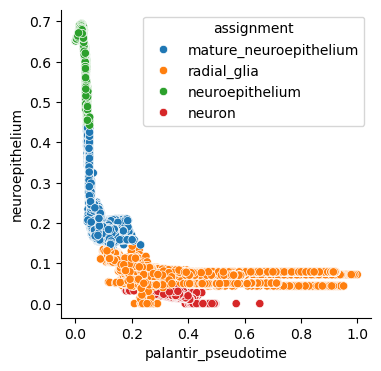

In [47]:
sns.scatterplot(data=branch_probs,  y='neuroepithelium', x='palantir_pseudotime', hue='assignment')

<Axes: xlabel='palantir_pseudotime', ylabel='neuroepithelium'>

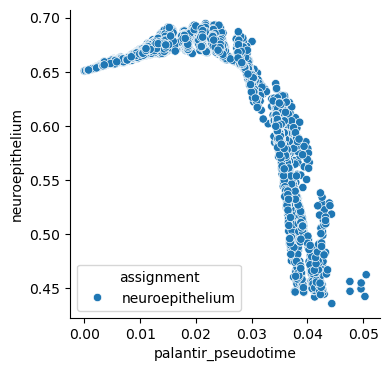

In [48]:
sns.scatterplot(data=branch_probs[branch_probs['assignment'] == 'neuroepithelium'], 
                y='neuroepithelium', x='palantir_pseudotime', hue='assignment')

<Axes: xlabel='palantir_pseudotime', ylabel='mature_neuroepithelium'>

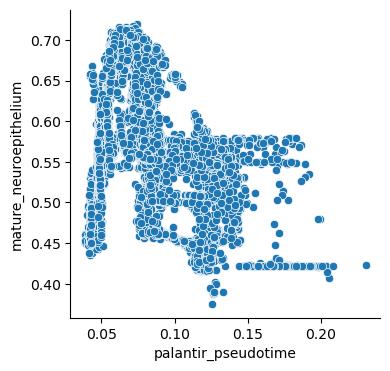

In [49]:
sns.scatterplot(data=branch_probs[branch_probs['assignment'] == 'mature_neuroepithelium'], 
                y='mature_neuroepithelium', x='palantir_pseudotime')

<Axes: xlabel='palantir_pseudotime', ylabel='radial_glia'>

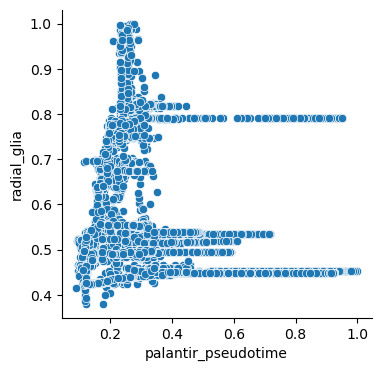

In [50]:
sns.scatterplot(data=branch_probs[branch_probs['assignment'] == 'radial_glia'], 
                y='radial_glia', x='palantir_pseudotime')

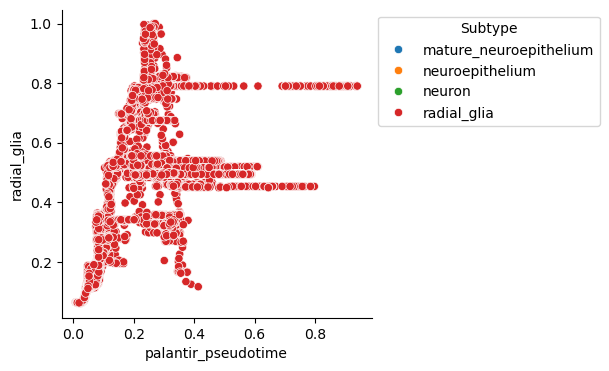

In [51]:
sns.scatterplot(data=branch_probs[branch_probs['subtype_collapsed_annot_no_markers'].str.contains('radial_glia')], 
                y='radial_glia', x='palantir_pseudotime', hue='subtype_collapsed_annot_no_markers', legend='full')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), title='Subtype')

In [52]:
organoids_purified.obs[['subclass_annot', 'subtype_collapsed_annot_no_markers']].value_counts()

subclass_annot                           subtype_collapsed_annot_no_markers
neuroepithelium XACT+ JARID2+ GABRB3+    neuroepithelium                       9657
neuron DCX+ MAP2+                        neuron                                6993
radial glia SLIT2+ WLS+ RMST+            radial_glia                           6686
mature neuroepithelium GPC3+ FN1+ P3H2+  mature_neuroepithelium                4213
radial glia SOX4+ ACTB+                  radial_glia                           4011
radial glia PAX3+ ZEB2+ SOX6+            radial_glia                            720
Name: count, dtype: int64

<Axes: xlabel='palantir_pseudotime', ylabel='neuron'>

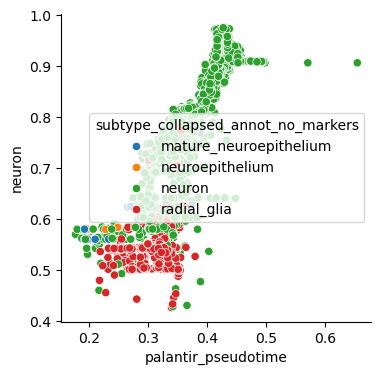

In [53]:
sns.scatterplot(data=branch_probs[branch_probs['assignment'] == 'neuron'], 
                y='neuron', x='palantir_pseudotime', hue='subtype_collapsed_annot_no_markers')

<Axes: xlabel='palantir_pseudotime', ylabel='neuron'>

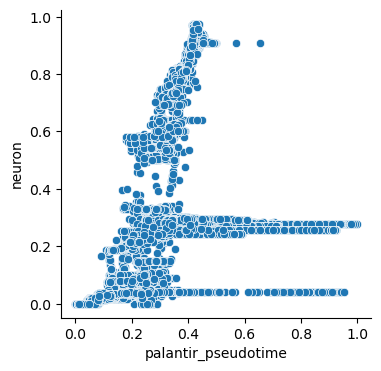

In [54]:
sns.scatterplot(data=branch_probs, y='neuron', x='palantir_pseudotime')

(0.0, 0.5)

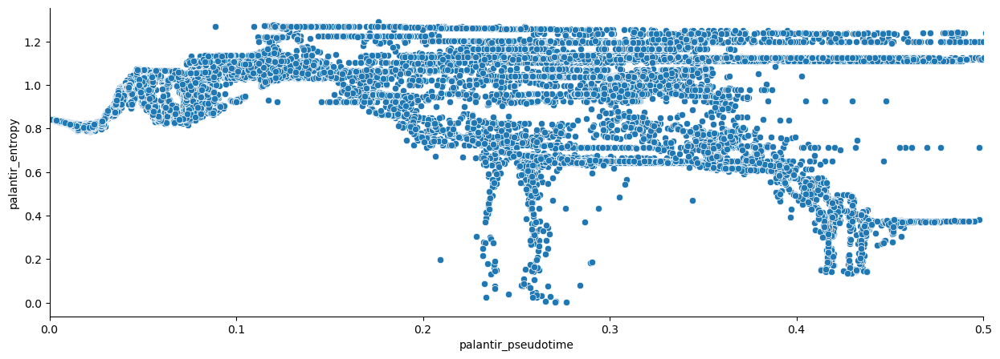

In [55]:
plt.figure(figsize=(15,5))
sns.scatterplot(data=organoids_purified.obs, y='palantir_entropy', x='palantir_pseudotime')
plt.xlim(0,0.5)

In [57]:
branch_probs['Day_condensed'] = organoids_purified.obs['Day_condensed']
branch_probs['subclass_annot'] = organoids_purified.obs['subclass_annot']

In [ ]:
# ## SAVE LOAD ##

# ORGANOIDS_PATH_REFINED = '/home/deepak/datasets/developing_hippocampus/roussos_organoid_snrnaseq/neocortical_refined/'
# organoids_filename = 'neocortical_organoids_with_force_direction.h5ad'
# #organoids_purified.write_h5ad(os.path.join(ORGANOIDS_PATH_REFINED, organoids_filename))

# organoids_purified = sc.read_h5ad(os.path.join(ORGANOIDS_PATH_REFINED, organoids_filename))

In [58]:
## Removing Backwards Connections ##

terminal_states = ["neuroepithelium", "mature_neuroepithelium", "radial_glia", "neuron"]
suffixes = ["_D10", "_D20" "_D35", "_D50", "_D90"]

# Build labels
all_labels = [state + day for day in suffixes for state in terminal_states]

# Allowed transitions (by index in terminal_states)
allowed_edges = {
    0: [0, 1, 2, 3],  # early → early or mature
    1: [1, 2, 3],  # mature → mature or RG
    2: [2, 3],  # RG → RG or neuron
    3: [3]      # neuron → neuron only
}

source = []
target = []
value = []

# Build edges across days
for d in range(len(suffixes) - 1):
    day = suffixes[d].replace("_", "")
    next_day = suffixes[d+1].replace("_", "")
    
    # Subset branch_probs for this day
    branch_probs_day = branch_probs[branch_probs['Day_condensed'] == day]
    branch_probs_day = branch_probs_day[terminal_states]
    branch_probs_day['subtype_collapsed_annot_no_markers'] = organoids_purified.obs['subtype_collapsed_annot_no_markers']
    branch_probs_day = branch_probs_day.groupby('subtype_collapsed_annot_no_markers').mean()
    
    for i, state in enumerate(terminal_states):
        src_index = d * len(terminal_states) + i
        for j in allowed_edges[i]:
            tgt_index = (d+1) * len(terminal_states) + j
            # average probability of flowing into that fate
            if state in branch_probs_day.index:
                v = branch_probs_day.loc[state, terminal_states[j]]
                if v > 0:
                    source.append(src_index)
                    target.append(tgt_index)
                    value.append(v)

# Plot
fig = go.Figure(data=[go.Sankey(
    arrangement="fixed",
    node=dict(
        pad=15,
        thickness=20,
        label=all_labels,
        color="skyblue"
    ),
    link=dict(
        source=source,
        target=target,
        value=value
    )
)])

fig.update_layout(title_text="Forward-only pseudotime → terminal fate flows", font_size=12)
fig.show()


/tmp/ipykernel_10992/1350572692.py:30: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_10992/1350572692.py:30: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_10992/1350572692.py:30: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



In [67]:
## Removing Backwards Connections ##

## Adding Color ##

terminal_states = ["neuroepithelium", "mature_neuroepithelium", "radial_glia", "neuron"]
suffixes = ["_D10", "_D20", "_D35", "_D50", "_D90"]

# Build labels
all_labels = [state + day for day in suffixes for state in terminal_states]

# Allowed transitions (by index in terminal_states)
allowed_edges = {
    0: [0, 1, 2, 3],  # early → early or mature
    1: [1, 2, 3],  # mature → mature or RG
    2: [2, 3],  # RG → RG or neuron
    3: [3]      # neuron → neuron only
}

source = []
target = []
value = []

# Build edges across days
for d in range(len(suffixes) - 1):
    day = suffixes[d].replace("_", "")
    next_day = suffixes[d+1].replace("_", "")
    
    # Subset branch_probs for this day
    branch_probs_day = branch_probs[branch_probs['Day_condensed'] == day]
    branch_probs_day = branch_probs_day[terminal_states]
    branch_probs_day['subtype_collapsed_annot_no_markers'] = organoids_purified.obs['subtype_collapsed_annot_no_markers']
    branch_probs_day = branch_probs_day.groupby('subtype_collapsed_annot_no_markers').mean()
    
    for i, state in enumerate(terminal_states):
        src_index = d * len(terminal_states) + i
        for j in allowed_edges[i]:
            tgt_index = (d+1) * len(terminal_states) + j
            # average probability of flowing into that fate
            if state in branch_probs_day.index:
                v = branch_probs_day.loc[state, terminal_states[j]]
                if v > 0:
                    source.append(src_index)
                    target.append(tgt_index)
                    value.append(v)

# Color code #

# Step 1: find most likely forward path from early_D10
forward_path = []
state_idx = 0  # early neuroepithelum index in terminal_states
for d in range(len(suffixes) - 1):
    src = d * len(terminal_states) + state_idx
    # find best outgoing edge
    candidates = [(s, t, v) for s, t, v in zip(source, target, value) if s == src]
    if not candidates: 
        break
    best = max(candidates, key=lambda x: x[2])
    forward_path.append((best[0], best[1]))
    state_idx = best[1] % len(terminal_states)  # update state for next step

# Step 2: find most likely path to neuron (for EACH D10 start)
all_paths_to_neuron = {}  # {start_index: [(src, tgt), ...]}
all_path_probs = {}       # {start_index: probability}

n_days = len(suffixes)
n_states = len(terminal_states)

# build adjacency dict
edges = {}
for s, t, v in zip(source, target, value):
    edges.setdefault(s, []).append((t, v))

# dynamic programming: best prob of reaching neuron from each node
best_prob = {}
best_next = {}

# final day neuron(s) prob=1, others=0
for i in range(n_states):
    idx = (n_days-1)*n_states + i
    best_prob[idx] = 1.0 if i == 3 else 0.0

# work backwards
for d in reversed(range(n_days-1)):
    for i in range(n_states):
        idx = d*n_states + i
        best = (0.0, None)
        for tgt, v in edges.get(idx, []):
            p = v * best_prob.get(tgt, 0.0)
            if p > best[0]:
                best = (p, tgt)
        best_prob[idx] = best[0]
        best_next[idx] = best[1]

# reconstruct path for EACH D10 start
for i in range(n_states):
    start_idx = 0*n_states + i  # day 0 index
    cur = i
    path = []
    prob = best_prob[start_idx]
    src = start_idx

    for d in range(n_days-1):
        tgt = best_next.get(src)
        if tgt is None:
            break
        path.append((src, tgt))
        cur = tgt % n_states
        src = tgt
        if cur == 3:  # reached neuron
            # auto-extend neuron→neuron
            for dd in range(d+1, n_days-1):
                src = dd*n_states + 3
                tgt = (dd+1)*n_states + 3
                path.append((src, tgt))
            break

    all_paths_to_neuron[i] = path
    all_path_probs[i] = prob

# Example: print them
for i, state in enumerate(terminal_states):
    start_idx = i
    print(f"{state} (D10) → neuron path (p={all_path_probs[start_idx]:.4f}):")
    print([all_labels[s] + "→" + all_labels[t] for s, t in all_paths_to_neuron[start_idx]])
    print()


# Step 3: assign colors along most likely paths

subtype_colors = {
    "neuroepithelium": "#ff7f00",          # orange
    "mature_neuroepithelium": "#377eb8",   # blue
    "radial_glia": "#e41a1c",              # red
    "neuron": "#4daf4a"                     # green
}

# Map edges along the most probable paths to neuron
highlight_links = {}
for start_idx, path in all_paths_to_neuron.items():
    for s, t in path:
        tgt_subtype = all_labels[s].split('_D')[0]  # color by the **target** subtype
        highlight_links[(s, t)] = subtype_colors.get(tgt_subtype, "lightgray")

# Assign link colors
link_colors = []
for s, t in zip(source, target):
    if (s, t) in highlight_links:
        link_colors.append(highlight_links[(s, t)])
    else:
        link_colors.append("rgba(180,180,180,0.2)")  # muted gray background

# Sankey
fig = go.Figure(data=[go.Sankey(
    arrangement="fixed",
    node=dict(
        pad=15,
        thickness=20,
        label=all_labels,
        color="lightgray"
    ),
    link=dict(
        source=source,
        target=target,
        value=value,
        color=link_colors
    )
)])

fig.update_layout(title_text="Most Likely Neuron Paths from Each D10 Start", font_size=12)
fig.write_image('/home/deepak/repositories/hippocampus/panels/sankey_road_to_neuron.svg')
fig.show()


neuroepithelium (D10) → neuron path (p=0.0332):
['neuroepithelium_D10→mature_neuroepithelium_D20', 'mature_neuroepithelium_D20→radial_glia_D35', 'radial_glia_D35→radial_glia_D50', 'radial_glia_D50→neuron_D90']

mature_neuroepithelium (D10) → neuron path (p=0.0387):
['mature_neuroepithelium_D10→mature_neuroepithelium_D20', 'mature_neuroepithelium_D20→radial_glia_D35', 'radial_glia_D35→radial_glia_D50', 'radial_glia_D50→neuron_D90']

radial_glia (D10) → neuron path (p=0.0410):
['radial_glia_D10→radial_glia_D20', 'radial_glia_D20→radial_glia_D35', 'radial_glia_D35→radial_glia_D50', 'radial_glia_D50→neuron_D90']

neuron (D10) → neuron path (p=0.0008):
['neuron_D10→neuron_D20', 'neuron_D20→neuron_D35', 'neuron_D35→neuron_D50', 'neuron_D50→neuron_D90']



/tmp/ipykernel_10992/1963380031.py:32: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_10992/1963380031.py:32: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_10992/1963380031.py:32: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_10992/1963380031.py:32: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observ

In [68]:
## Removing Backwards Connections ##

## Adding Color ##

terminal_states = ["neuroepithelium", "mature_neuroepithelium", "radial_glia", "neuron"]
suffixes = ["_D10", "_D20", "_D35", "_D50", "_D90"]

# Build labels
all_labels = [state + day for day in suffixes for state in terminal_states]

# Allowed transitions (by index in terminal_states)
allowed_edges = {
    0: [0, 1, 2, 3],  # early → early or mature
    1: [1, 2, 3],  # mature → mature or RG
    2: [2, 3],  # RG → RG or neuron
    3: [3]      # neuron → neuron only
}

source = []
target = []
value = []

# Build edges across days
for d in range(len(suffixes) - 1):
    day = suffixes[d].replace("_", "")
    next_day = suffixes[d+1].replace("_", "")
    
    # Subset branch_probs for this day
    branch_probs_day = branch_probs[branch_probs['Day_condensed'] == day]
    branch_probs_day = branch_probs_day[terminal_states]
    branch_probs_day['subtype_collapsed_annot_no_markers'] = organoids_purified.obs['subtype_collapsed_annot_no_markers']
    branch_probs_day = branch_probs_day.groupby('subtype_collapsed_annot_no_markers').mean()
    
    for i, state in enumerate(terminal_states):
        src_index = d * len(terminal_states) + i
        for j in allowed_edges[i]:
            tgt_index = (d+1) * len(terminal_states) + j
            # average probability of flowing into that fate
            if state in branch_probs_day.index:
                v = branch_probs_day.loc[state, terminal_states[j]]
                if v > 0:
                    source.append(src_index)
                    target.append(tgt_index)
                    value.append(v)

# Color code #

# Step 1: find most likely forward path from early_D10
forward_path = []
state_idx = 0  # early neuroepithelum index in terminal_states
for d in range(len(suffixes) - 1):
    src = d * len(terminal_states) + state_idx
    # find best outgoing edge
    candidates = [(s, t, v) for s, t, v in zip(source, target, value) if s == src]
    if not candidates: 
        break
    best = max(candidates, key=lambda x: x[2])
    forward_path.append((best[0], best[1]))
    state_idx = best[1] % len(terminal_states)  # update state for next step

# Step 2: find most likely path to neuron (for EACH D10 start)
all_paths_to_neuron = {}  # {start_index: [(src, tgt), ...]}
all_path_probs = {}       # {start_index: probability}

n_days = len(suffixes)
n_states = len(terminal_states)

# build adjacency dict
edges = {}
for s, t, v in zip(source, target, value):
    edges.setdefault(s, []).append((t, v))

# dynamic programming: best prob of reaching neuron from each node
best_prob = {}
best_next = {}

# final day neuron(s) prob=1, others=0
for i in range(n_states):
    idx = (n_days-1)*n_states + i
    best_prob[idx] = 1.0 if i == 3 else 0.0

# work backwards
for d in reversed(range(n_days-1)):
    for i in range(n_states):
        idx = d*n_states + i
        best = (0.0, None)
        for tgt, v in edges.get(idx, []):
            p = v * best_prob.get(tgt, 0.0)
            if p > best[0]:
                best = (p, tgt)
        best_prob[idx] = best[0]
        best_next[idx] = best[1]

# reconstruct path for EACH D10 start
for i in range(n_states):
    start_idx = 0*n_states + i  # day 0 index
    cur = i
    path = []
    prob = best_prob[start_idx]
    src = start_idx

    for d in range(n_days-1):
        tgt = best_next.get(src)
        if tgt is None:
            break
        path.append((src, tgt))
        cur = tgt % n_states
        src = tgt
        if cur == 3:  # reached neuron
            # auto-extend neuron→neuron
            for dd in range(d+1, n_days-1):
                src = dd*n_states + 3
                tgt = (dd+1)*n_states + 3
                path.append((src, tgt))
            break

    all_paths_to_neuron[i] = path
    all_path_probs[i] = prob

# Example: print them
for i, state in enumerate(terminal_states):
    start_idx = i
    print(f"{state} (D10) → neuron path (p={all_path_probs[start_idx]:.4f}):")
    print([all_labels[s] + "→" + all_labels[t] for s, t in all_paths_to_neuron[start_idx]])
    print()


# Step 3: assign colors

# --- specify colors for each subtype (hex) ---
subtype_colors = {
    "neuroepithelium": "#ff7f0e",  # blue
    "mature_neuroepithelium":  "#1f77b4", # orange
    "radial_glia": "#2ca02c",  # green
    "neuron": "#d62728"  # red
}

# --- assign per-link colors based on the starting subtype ---
link_colors = []
for s, t in zip(source, target):
    source_subtype = all_labels[s][:-4]  # remove "_Dx"
    target_subtype = all_labels[t][:-4]
    
    if source_subtype == target_subtype:
        link_colors.append(subtype_colors.get(source_subtype, "#cccccc"))
    else:
        link_colors.append("rgba(200,200,200,0.4)")  # muted gray for other edges

# --- Sankey figure ---
fig = go.Figure(data=[go.Sankey(
    arrangement="fixed",
    node=dict(
        pad=15,
        thickness=20,
        label=all_labels,
        color="lightgray"
    ),
    link=dict(
        source=source,
        target=target,
        value=value,
        color=link_colors
    )
)])

fig.update_layout(
    title_text="Neuron Paths Colored by Starting Subtype",
    font_size=12
)
fig.write_image('/home/deepak/repositories/hippocampus/panels/sankey_stalling.svg')
fig.show()



neuroepithelium (D10) → neuron path (p=0.0332):
['neuroepithelium_D10→mature_neuroepithelium_D20', 'mature_neuroepithelium_D20→radial_glia_D35', 'radial_glia_D35→radial_glia_D50', 'radial_glia_D50→neuron_D90']

mature_neuroepithelium (D10) → neuron path (p=0.0387):
['mature_neuroepithelium_D10→mature_neuroepithelium_D20', 'mature_neuroepithelium_D20→radial_glia_D35', 'radial_glia_D35→radial_glia_D50', 'radial_glia_D50→neuron_D90']

radial_glia (D10) → neuron path (p=0.0410):
['radial_glia_D10→radial_glia_D20', 'radial_glia_D20→radial_glia_D35', 'radial_glia_D35→radial_glia_D50', 'radial_glia_D50→neuron_D90']

neuron (D10) → neuron path (p=0.0008):
['neuron_D10→neuron_D20', 'neuron_D20→neuron_D35', 'neuron_D35→neuron_D50', 'neuron_D50→neuron_D90']



/tmp/ipykernel_10992/2750365122.py:32: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_10992/2750365122.py:32: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_10992/2750365122.py:32: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_10992/2750365122.py:32: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observ

In [69]:
import numpy as np
import networkx as nx
import plotly.graph_objects as go

# --- Build a DAG from your Sankey edges ---
eps = 1e-12  # to avoid log(0)
G = nx.DiGraph()
for i, lbl in enumerate(all_labels):
    G.add_node(i, label=lbl)

for s, t, v in zip(source, target, value):
    if v > 0:
        cost = -np.log(v + eps)     # larger prob => smaller cost
        G.add_edge(s, t, prob=v, cost=cost)

# --- Helper: get node index by (day_index, state_index) ---
n_states = len(terminal_states)
def node_idx(day_i, state_i):
    return day_i * n_states + state_i

# indices for D10 starts (day 0) and neuron at D90 (last day)
start_nodes = [node_idx(0, i) for i in range(n_states)]               # all four D10 states
target_node = node_idx(len(suffixes)-1, terminal_states.index("neuron"))

# --- Top-K most probable paths to neuron for EACH D10 start ---
K = 3  # number of distinct routes to show per start
paths_per_start = {}      # start_node -> list of paths (each path is list of node indices)
probs_per_start = {}      # start_node -> list of path probabilities

for s0 in start_nodes:
    # Skip if starting at neuron_D10 (optional)
    # if s0 % n_states == terminal_states.index("neuron"):
    #     continue

    if not nx.has_path(G, s0, target_node):
        paths_per_start[s0] = []
        probs_per_start[s0] = []
        continue

    # shortest_simple_paths gives paths sorted by total cost; we take first K
    gen = nx.shortest_simple_paths(G, source=s0, target=target_node, weight="cost")
    paths = []
    probs = []
    for k, p in enumerate(gen):
        if k >= K:
            break
        # path probability = product of edge probabilities along the path
        edge_probs = []
        for u, v in zip(p[:-1], p[1:]):
            edge_probs.append(G[u][v]["prob"])
        paths.append(p)
        probs.append(float(np.prod(edge_probs)))

    paths_per_start[s0] = paths
    probs_per_start[s0] = probs

# --- Build a color per edge depending on which top-K paths include it ---
# Base: light gray for everything
link_colors = ["rgba(180,180,180,0.25)"] * len(source)

# assign a distinct palette per start state
palette = {
    0: ["#e41a1c", "#fb9a99", "#fcbba1"],  # early NE starts: strong red → lighter
    1: ["#377eb8", "#9ecae1", "#bdd7e7"],  # mature NE: blues
    2: ["#4daf4a", "#a1d99b", "#c7e9c0"],  # RG: greens
    3: ["#984ea3", "#bcbddc", "#dadaeb"],  # neuron: purples (in case you keep it)
}

# Map (s,t) -> first path/color that uses it (or blend if you want)
edge_to_color = {}

for s0, paths in paths_per_start.items():
    for rank, path in enumerate(paths):
        col = palette[s0 % n_states][min(rank, len(palette[s0 % n_states]) - 1)]
        # mark each edge on this path
        for u, v in zip(path[:-1], path[1:]):
            # locate this link in the Sankey arrays (could be multiple; color them all)
            for i, (S, T) in enumerate(zip(source, target)):
                if S == u and T == v:
                    # prefer to keep the strongest (rank 0) color if multiple paths hit same edge
                    # only override if this is a better rank (smaller)
                    if i not in edge_to_color or rank < edge_to_color[i][0]:
                        edge_to_color[i] = (rank, col)

# apply colors
for i, info in edge_to_color.items():
    link_colors[i] = info[1]

# Optionally thicken links that are on any highlighted path
highlight_values = value.copy()
for i in edge_to_color.keys():
    # amplify width for visibility (does not change probabilities)
    highlight_values[i] = max(value[i], np.percentile(value, 90))

# --- Plot the Sankey with highlighted multi-path routes ---
fig = go.Figure(data=[go.Sankey(
    arrangement="fixed",
    node=dict(
        pad=15,
        thickness=20,
        label=all_labels,
        color="lightgray",
        line=dict(color="black", width=0.3)
    ),
    link=dict(
        source=source,
        target=target,
        value=highlight_values,
        color=link_colors
    )
)])

fig.update_layout(
    title_text="Top-K most probable trajectories to D90 neuron (per D10 start)",
    font_size=12
)
fig.show()

# --- (Optional) print the routes in text for inspection ---
for s0, paths in paths_per_start.items():
    start_label = all_labels[s0]
    print(f"\nStart {start_label} → D90 neuron: top {len(paths)} routes")
    for k, (p, pr) in enumerate(zip(paths, probs_per_start[s0])):
        lab_path = " → ".join(all_labels[i] for i in p)
        print(f"  #{k+1}  P={pr:.4g}  {lab_path}")



Start neuroepithelium_D10 → D90 neuron: top 3 routes
  #1  P=0.03317  neuroepithelium_D10 → mature_neuroepithelium_D20 → radial_glia_D35 → radial_glia_D50 → neuron_D90
  #2  P=0.02881  neuroepithelium_D10 → neuroepithelium_D20 → mature_neuroepithelium_D35 → radial_glia_D50 → neuron_D90
  #3  P=0.02239  neuroepithelium_D10 → mature_neuroepithelium_D20 → radial_glia_D35 → neuron_D50 → neuron_D90

Start mature_neuroepithelium_D10 → D90 neuron: top 3 routes
  #1  P=0.03871  mature_neuroepithelium_D10 → mature_neuroepithelium_D20 → radial_glia_D35 → radial_glia_D50 → neuron_D90
  #2  P=0.02613  mature_neuroepithelium_D10 → mature_neuroepithelium_D20 → radial_glia_D35 → neuron_D50 → neuron_D90
  #3  P=0.02576  mature_neuroepithelium_D10 → mature_neuroepithelium_D20 → mature_neuroepithelium_D35 → radial_glia_D50 → neuron_D90

Start radial_glia_D10 → D90 neuron: top 3 routes
  #1  P=0.04103  radial_glia_D10 → radial_glia_D20 → radial_glia_D35 → radial_glia_D50 → neuron_D90
  #2  P=0.02769  ra

In [ ]:
# conditional on 

## early --> early --> early --> mature --> early --> early
# mature --> mature  --> mature --> mature --> mature --> mature
# neuron --> neuron --> neuron --> neuron --> neuron --> neuron
# radial glia --> radial glia --> radial glia --> radial glia -> radial glia --> neuron 

# after d35 early is more likely to stay early, itll transition at d21 when its most likely otherwise mot likely to stay

In [473]:
## can you show that at every stage RG is the highest probabilty stage to neuron
## can you show that at every what is the most likely mature neuroepithelium ##
## can you show what type of RG has the highest probability of transitioning , if that even matters

In [73]:
## Calculate Terminal Points ##

terminals_subtype_dict = {}

for cluster in organoids_purified.obs['subtype_annot'].value_counts().index:
    
    d90_mask = organoids_purified.obs['Day'] == 'D90'
    
    d90_coords = organoids_purified.obsm['X_draw_graph_ForceAtlas'][d90_mask]
    
    # Step 3: (Optional) Filter D90 further by subclass_annot (e.g., '1-1s')
    subclass_mask = (organoids_purified.obs['subtype_annot'] == cluster)
    d90_subclass_mask = d90_mask & subclass_mask
    d90_cluster_coords = organoids_purified.obsm['X_draw_graph_ForceAtlas'][d90_subclass_mask]
    d90_cluster_centroid = d90_cluster_coords.mean(axis=0)
    
    # Step 4: Compute distances from D90 cells to the centroid
    distances = np.linalg.norm(d90_cluster_coords - d90_cluster_centroid, axis=1)
    
    # Step 5: Find index of the closest point (within D90 cells)
    closest_idx_within_d90 = np.argmin(distances)
     
    # Get the original index of the closest D90 point to the centroid
    d90_subclass_indices = np.where(d90_subclass_mask)[0]
    closest_index = d90_subclass_indices[closest_idx_within_d90]
    
    # (Optional) Get the actual index label if needed
    closest_index_label = organoids_purified.obs_names[closest_index]

    terminals_subtype_dict[cluster] = closest_index_label

In [74]:
## Set Terminal States and Visualize ##

organoids_purified.obs['terminal_states_subtype'] = organoids_purified.obs['subtype_annot']
organoids_purified.obs['terminal_states_subtype'] = organoids_purified.obs['terminal_states_subtype'].astype('str')
organoids_purified.obs.loc[(organoids_purified.obs_names.isin(terminals_dict.values())), 'terminal_states_subtype'] = 'terminal_state'

organoids_purified.obs.loc[starting_label, 'terminal_states_subtype'] = 'starting_state'

terminals_subtype_states = pd.Series(data=list(terminals_subtype_dict.keys()), index=list(terminals_subtype_dict.values()))

In [75]:
organoids_purified_copied = organoids_purified.copy()

In [76]:
organoids_purified_copied[organoids_purified_copied.obs['Day'] == 'D90'].obs['subtype_annot'].value_counts()

subtype_annot
neuroepithelium XACT+ JARID2+ GABRB3+                2391
excitatory neuron MAP2+ DCX+ GRIA4+ GRIA1+ FGF14+    2148
radial glia SLIT2+ WLS+ RMST+                        2014
radial glia SOX4+ ACTB+                               909
radial glia neuroblast SOX6+ PDZRN3+ FBN2+            644
mature neuroepithelium GPC3+ FN1+ P3H2+               569
neuroepithelial neuroblast MAP2+ DCX+ XACT+           179
cranial placode neuron ISL1+ SDK1+ + EBF1–3+           70
radial glia PAX3+ ZEB2+ SOX6+                          70
Name: count, dtype: int64

In [77]:
pr_res_subtypes = palantir.core.run_palantir(organoids_purified_copied, starting_label, eigvec_key='DM_EigenVectors',
                                    num_waypoints=500, terminal_states=terminals_subtype_states)

Sampling and flocking waypoints...
Time for determining waypoints: 0.009242804845174153 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...


/home/deepak/pixi_envs/pegasus/.pixi/envs/default/lib/python3.10/site-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning:

os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.



Time for shortest paths: 0.22241408824920655 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9987
Correlation at iteration 2: 0.9999
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


<Axes: ylabel='subtype_annot'>

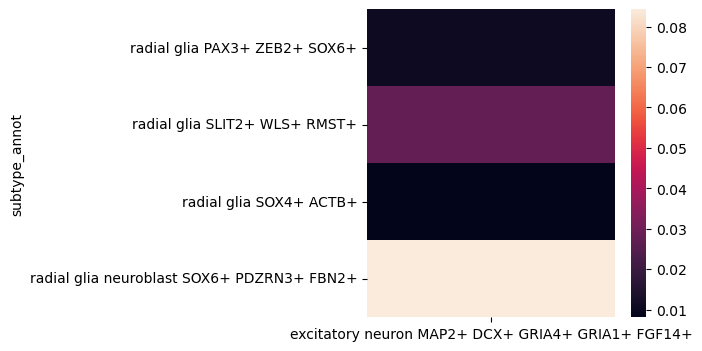

In [80]:
branch_probs_subtype = pr_res_subtypes.branch_probs
branch_probs_subtype['subtype_annot'] = organoids_purified.obs['subtype_annot']
branch_probs_subtype['subtype_annot'] = branch_probs_subtype['subtype_annot'].astype('str')

heatmapable = branch_probs_subtype[branch_probs_subtype['subtype_annot'].str.contains('radial glia').values].groupby('subtype_annot').mean()
sns.heatmap(heatmapable[['excitatory neuron MAP2+ DCX+ GRIA4+ GRIA1+ FGF14+']])

In [85]:
# ## Removing Backwards Connections ##

# ## Adding Color ##

# terminal_states_subtype = list(terminals_subtype_dict.keys())
# suffixes = ["_D10", "_D18", "_D21", "_D35", "_D50", "_D90"]

# # Build labels
# all_labels = [state + day for day in suffixes for state in terminal_states_subtype]

# # Allowed transitions (by index in terminal_states_subtype)
# allowed_edges = {
#     0: [0, 1, 2, 3, 4, 5, 6, 7],  # early → early or mature
#     1: [1, 2, 3, 4, 5, 6, 7],  # mature → mature or RG
#     2: [2,  3, 4, 5, 6, 7],  # RG → RG or neuron
#     3: [3], # excitatory projection neuron
#     4: [3, 4, 5, 6, 7], # classic radial glia, not to early but to the rest?
#     5: [4, 5, 6, 7],
#     6: [4, 5, 6, 7],
#     7: [7]
# }

# source = []
# target = []
# value = []

# # Build edges across days
# for d in range(len(suffixes) - 1):
#     day = suffixes[d].replace("_", "")
#     next_day = suffixes[d+1].replace("_", "")
    
#     # Subset branch_probs for this day
#     branch_probs_subtype = pr_res_subtypes.branch_probs
#     branch_probs_subtype['Day'] = organoids_purified_copied.obs['Day']
#     branch_probs_day = branch_probs_subtype[branch_probs_subtype['Day'] == day]
#     branch_probs_day = branch_probs_day[terminal_states_subtype]
#     branch_probs_day['subtype_annot'] = organoids_purified.obs['subtype_annot']
#     branch_probs_day = branch_probs_day.groupby('subtype_annot').mean()
    
#     for i, state in enumerate(terminal_states_subtype):
#         src_index = d * len(terminal_states_subtype) + i
#         for j in allowed_edges[i]:
#             tgt_index = (d+1) * len(terminal_states_subtype) + j
#             # average probability of flowing into that fate
#             if state in branch_probs_day.index:
#                 v = branch_probs_day.loc[state, terminal_states_subtype[j]]
#                 if v > 0:
#                     source.append(src_index)
#                     target.append(tgt_index)
#                     value.append(v)

# # Color code #

# # Step 1: find most likely forward path from early_D10
# forward_path = []
# state_idx = 0  # early neuroepithelum index in terminal_states
# for d in range(len(suffixes) - 1):
#     src = d * len(terminal_states_subtype) + state_idx
#     # find best outgoing edge
#     candidates = [(s, t, v) for s, t, v in zip(source, target, value) if s == src]
#     if not candidates: 
#         break
#     best = max(candidates, key=lambda x: x[2])
#     forward_path.append((best[0], best[1]))
#     state_idx = best[1] % len(terminal_states_subtype)  # update state for next step

# # Step 2: find most likely path to neuron (for EACH D10 start)
# all_paths_to_neuron = {}  # {start_index: [(src, tgt), ...]}
# all_path_probs = {}       # {start_index: probability}

# n_days = len(suffixes)
# n_states = len(terminal_states_subtype)

# # build adjacency dict
# edges = {}
# for s, t, v in zip(source, target, value):
#     edges.setdefault(s, []).append((t, v))

# # dynamic programming: best prob of reaching neuron from each node
# best_prob = {}
# best_next = {}

# # final day neuron(s) prob=1, others=0
# for i in range(n_states):
#     idx = (n_days-1)*n_states + i
#     best_prob[idx] = 1.0 if i == 3 else 0.0

# # work backwards
# for d in reversed(range(n_days-1)):
#     for i in range(n_states):
#         idx = d*n_states + i
#         best = (0.0, None)
#         for tgt, v in edges.get(idx, []):
#             p = v * best_prob.get(tgt, 0.0)
#             if p > best[0]:
#                 best = (p, tgt)
#         best_prob[idx] = best[0]
#         best_next[idx] = best[1]

# # reconstruct path for EACH D10 start
# for i in range(n_states):
#     start_idx = 0*n_states + i  # day 0 index
#     cur = i
#     path = []
#     prob = best_prob[start_idx]
#     src = start_idx

#     for d in range(n_days-1):
#         tgt = best_next.get(src)
#         if tgt is None:
#             break
#         path.append((src, tgt))
#         cur = tgt % n_states
#         src = tgt
#         if cur == 3:  # reached neuron
#             # auto-extend neuron→neuron
#             for dd in range(d+1, n_days-1):
#                 src = dd*n_states + 3
#                 tgt = (dd+1)*n_states + 3
#                 path.append((src, tgt))
#             break

#     all_paths_to_neuron[i] = path
#     all_path_probs[i] = prob

# # Example: print them
# for i, state in enumerate(terminal_states_subtype):
#     start_idx = i
#     print(f"{state} (D10) → neuron path (p={all_path_probs[start_idx]:.4f}):")
#     print([all_labels[s] + "→" + all_labels[t] for s, t in all_paths_to_neuron[start_idx]])
#     print()


# # Step 3: assign colors

# # --- assign per-link colors based on best paths ---
# colors = ["red", "green", "blue", "orange"]  # one per D10 start
# highlight_links = {path_edge: colors[i] for i, path in all_paths.items() for path_edge in path}

# link_colors = []
# for s, t, v in zip(source, target, value):
#     if (s, t) in highlight_links:
#         link_colors.append(highlight_links[(s, t)])
#     else:
#         link_colors.append("rgba(200,200,200,0.2)")  # background gray

# import numpy as np
# import plotly.graph_objects as go

# # --- layout the grid ---
# n_states = len(terminal_states_subtype)
# n_days = len(suffixes)

# # assign x = time, y = subtype position
# x_positions = []
# y_positions = []

# for d in range(n_days):
#     for i in range(n_states):
#         x_positions.append(d / (n_days - 1))  # normalized 0→1 across days
#         y_positions.append(1 - (i / (n_states - 1)))  # subtype stacked top→bottom

# # --- Sankey with fixed layout ---
# fig = go.Figure(data=[go.Sankey(
#     arrangement="snap",  # respects x,y
#     node=dict(
#         pad=15,
#         thickness=20,
#         line=dict(color="black", width=0.5),
#         label=all_labels,
#         color="lightgray",
#         x=x_positions,
#         y=y_positions
#     ),
#     link=dict(
#         source=source,
#         target=target,
#         value=value,
#         color=link_colors
#     )
# )])

# fig.update_layout(
#     title_text="Most Likely Neuron Paths from Each D10 Start (Subtype Grid)",
#     font_size=12
# )
# fig.show()




In [83]:
import plotly.graph_objects as go

# ---- Define subtypes ----
subtypes = branch_probs_subtype.columns[0:-1].tolist()  # the target columns
n_states = len(subtypes)

# average transition probabilities by subtype_annot
avg_probs = branch_probs_subtype.groupby('subtype_annot').mean()

avg_probs = avg_probs[pd.Series(avg_probs.index).str.contains('glia').values]

# ---- Build edges, forbidding radial glia → neuroepithelium ----
source = []
target = []
value = []

threshold = 0.01

for src_sub in avg_probs.index:
    for tgt_sub in subtypes:
        # forbid radial glia → any neuroepithelium
        if ("glia" in src_sub.lower()) and ("neuroepithelium" in tgt_sub.lower()):
            continue
        v = avg_probs.loc[src_sub, tgt_sub]
        if v >= threshold:
            source.append(subtypes.index(src_sub))
            target.append(subtypes.index(tgt_sub))
            value.append(v)

# ---- Colors ----
link_colors = ["rgba(0,100,200,0.6)" for _ in range(len(source))]
node_colors = ["lightblue" if st != "excitatory projection neuron" else "orange" for st in subtypes]

# ---- Sankey ----
fig = go.Figure(data=[go.Sankey(
    arrangement="snap",  # lets Plotly auto-layout nodes nicely
    node=dict(
        pad=15,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=subtypes,
        color=node_colors
    ),
    link=dict(
        source=source,
        target=target,
        value=value,
        color=link_colors
    )
)])

fig.update_layout(
    title_text="Subtype Transition Probabilities → Excitatory Projection Neurons",
    font_size=12
)
fig.show()


In [98]:
pr_res_subtypes.branch_probs.columns.str.contains('radial')

array([False,  True, False,  True,  True, False,  True, False, False,
       False, False])

In [111]:
branching_subtypes = pr_res_subtypes.branch_probs

In [121]:
branching_subtypes

,cranial placode neuron ISL1+ SDK1+ + EBF1–3+,radial glia PAX3+ ZEB2+ SOX6+,excitatory neuron MAP2+ DCX+ GRIA4+ GRIA1+ FGF14+,radial glia neuroblast SOX6+ PDZRN3+ FBN2+,radial glia SOX4+ ACTB+,mature neuroepithelium GPC3+ FN1+ P3H2+,radial glia SLIT2+ WLS+ RMST+,neuroepithelium XACT+ JARID2+ GABRB3+,neuroepithelial neuroblast MAP2+ DCX+ XACT+,subtype_annot,Day
barcodekey,,,,,,,,,,,
AAACCAAAGCCAGGTT-Deepak-org-set5,0.000000,0.038904,0.000000,0.000000,0.040006,0.531438,0.000000,0.372906,0.0,neuroepithelium XACT+ JARID2+ GABRB3+,D21
AAACCAAAGCGACTAC-Deepak-org-set5,0.029932,0.156787,0.011633,0.019358,0.591736,0.093316,0.054379,0.033039,0.0,radial glia SOX4+ ACTB+,D21
AAACCATTCGATCGCG-Deepak-org-set5,0.029130,0.251337,0.011195,0.000000,0.167863,0.356047,0.055350,0.121649,0.0,radial glia SLIT2+ WLS+ RMST+,D21
AAACCCGCAGCCTAGA-Deepak-org-set5,0.017500,0.148714,0.000000,0.000000,0.116355,0.501978,0.033184,0.170836,0.0,mature neuroepithelium GPC3+ FN1+ P3H2+,D21
AAACGAATCTCATCTA-Deepak-org-set5,0.000000,0.080276,0.000000,0.000000,0.106714,0.568199,0.018724,0.209000,0.0,radial glia SOX4+ ACTB+,D21
...,...,...,...,...,...,...,...,...,...,...,...
TGGTAGTCAGTTAAGC-Deepak-org-set10,0.033142,0.281673,0.012742,0.000000,0.182034,0.312475,0.062829,0.106885,0.0,radial glia SOX4+ ACTB+,D21
TGGTGAGAGTGCCTAA-Deepak-org-set10,0.037581,0.355931,0.014435,0.000000,0.187950,0.240934,0.071584,0.082567,0.0,radial glia PAX3+ ZEB2+ SOX6+,D21
TGTCAGGCATTACTCG-Deepak-org-set10,0.000000,0.043284,0.000000,0.000000,0.043461,0.712979,0.000000,0.181698,0.0,neuroepithelium XACT+ JARID2+ GABRB3+,D21


In [128]:
branching_subtypes_rg = branching_subtypes[branching_subtypes['subtype_annot'].str.contains('radial')]

In [125]:
#branching_subtypes_rg = branching_subtypes_rg[~branching_subtypes_rg['subtype_annot'].str.contains('neuroblast')]

In [129]:
branching_subtypes_rg = branching_subtypes_rg[['excitatory neuron MAP2+ DCX+ GRIA4+ GRIA1+ FGF14+', 'subtype_annot']]

/tmp/ipykernel_10992/46086969.py:16: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




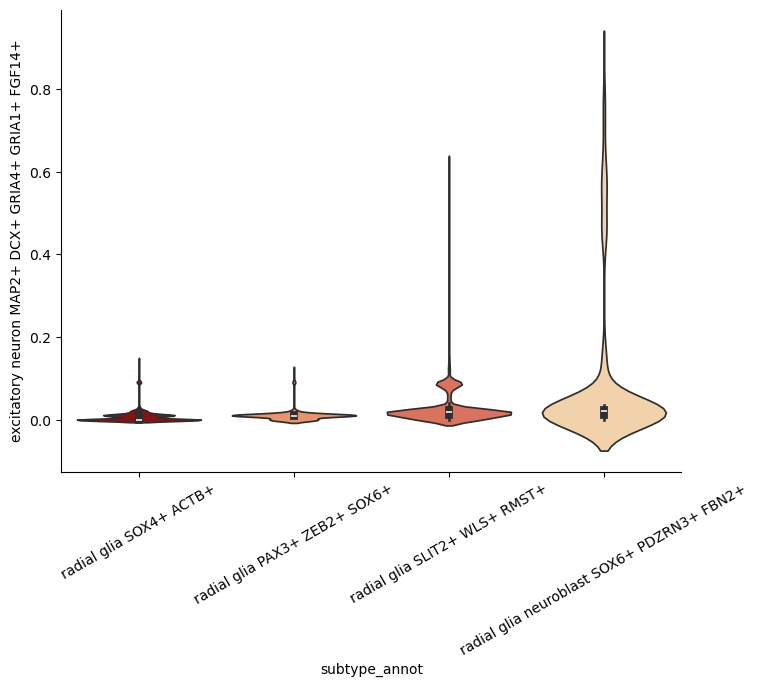

In [145]:
import seaborn as sns
import matplotlib.pyplot as plt

custom_colors = ['#990000', '#fc8d59', '#ef6548', '#fdd49e']

# Calculate the means for each 'subtype_annot'
mean_values = branching_subtypes_rg.groupby('subtype_annot')['excitatory neuron MAP2+ DCX+ GRIA4+ GRIA1+ FGF14+'].mean()

# Sort by the means
sorted_subtypes = mean_values.sort_values().index

# Create the figure and axes with the desired size
fig, ax = plt.subplots(figsize=(8, 6))  # Adjust figsize as needed

# Plot the violin plot with the 'order' parameter to sort by means
sns.violinplot(data=branching_subtypes_rg, x='subtype_annot', y='excitatory neuron MAP2+ DCX+ GRIA4+ GRIA1+ FGF14+',
               palette=custom_colors, ax=ax, order=sorted_subtypes)

# Rotate x-axis labels by 30 degrees
plt.xticks(rotation=30)

# Optionally, save the figure
# plt.savefig('/home/deepak/repositories/hippocampus/panels/branching_subtypes_violin.png', format='png')

# Show the plot
plt.show()


/tmp/ipykernel_10992/1582807373.py:14: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




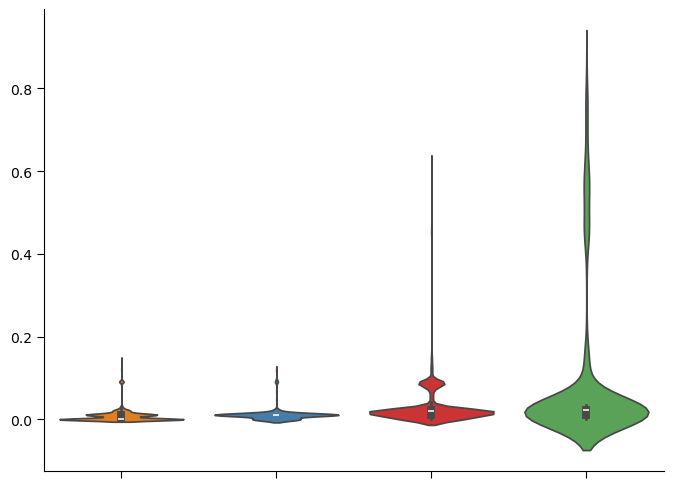

In [163]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the means for each 'subtype_annot'
mean_values = branching_subtypes_rg.groupby('subtype_annot')['excitatory neuron MAP2+ DCX+ GRIA4+ GRIA1+ FGF14+'].mean()

# Sort by the means
sorted_subtypes = mean_values.sort_values().index

# Create the figure and axes with the desired size
fig, ax = plt.subplots(figsize=(8, 6))  # Adjust figsize as needed

# Plot the violin plot with the 'order' parameter to sort by means
sns.violinplot(data=branching_subtypes_rg, x='subtype_annot', y='excitatory neuron MAP2+ DCX+ GRIA4+ GRIA1+ FGF14+',
               palette=custom_colors, ax=ax, order=sorted_subtypes)

# Rotate x-axis labels by 30 degrees (optional)
plt.xticks(rotation=30)

# Remove x-axis labels but keep the ticks (the notches)
ax.set_xticklabels([])  # Remove x-axis labels (text)
ax.tick_params(axis='x', which='both', length=5)  # Keep x-axis ticks (notches)

# Optionally, remove y-axis labels and ticks
#ax.set_yticklabels([])  # Remove y-axis labels
ax.set_title('')  # Remove title
ax.set_xlabel('')  # Remove x-label
ax.set_ylabel('')  # Remove y-label
ax.tick_params(axis='y', which='both', length=5)  # Remove y-axis ticks if needed

# Optionally, save the figure
plt.savefig('/home/deepak/repositories/hippocampus/panels/radial_glia_subtypes_neuron_probs.svg', format='svg')

# Show the plot
plt.show()


In [149]:
organoids_purified.obs.columns

Index(['n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts',
       'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes',
       'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',
       'pct_counts_in_top_500_genes', 'total_counts_mito',
       'log1p_total_counts_mito', 'pct_counts_mito', 'QC_pass', 'batch',
       'SubID_vs', 'gt_pass', 'Donor_ID', 'barcodes', 'set', 'Donor',
       'Condition', 'Day', 'Donor-Condition-Timepoint', 'n_counts',
       'percent_mito', 'Sex', 'G1/S', 'G2/M', 'cycle_diff', 'cycling',
       'predicted_phase', 'class', 'subclass', 'subtype', 'doublet_score',
       'pred_dbl', 'demux_type', 'braun_cellclass_pred', 'braun_tissue_pred',
       'sestan_full_pred', 'sestan_balanced_hipp_pred',
       'sestan_neocortex_pred', 'hnoca_celltype_pred', 'shendure_organ_pred',
       'shendure_organ_cell_pred', 'subtype_annot_markers', 'subtype_annot',
       'subclass_annot_markers', 'subclass_annot', 'class_subclass',
       'class_su

In [156]:
organoids_purified.obs['subtype_collapsed_annot_no_markers'] = pd.Categorical(organoids_purified.obs['subtype_collapsed_annot_no_markers'], ordered=True, 
               categories=['neuroepithelium', 'mature_neuroepithelium', 'radial_glia', 'neuron'])

/tmp/ipykernel_10992/1081823667.py:11: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




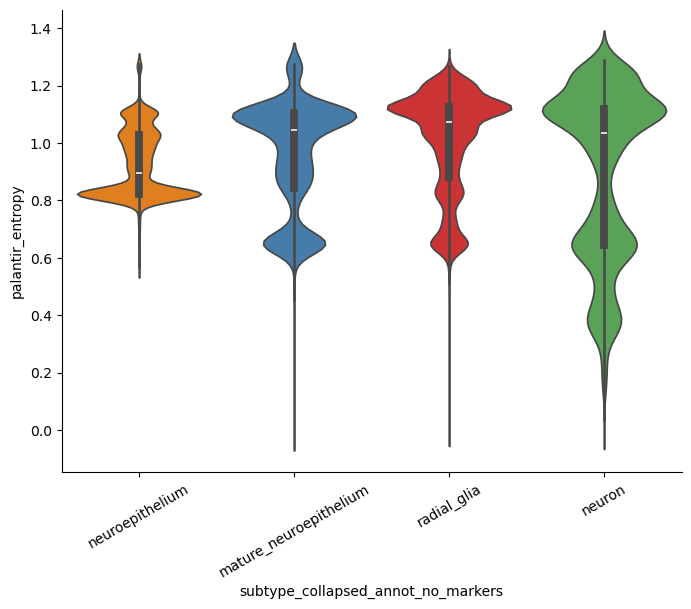

In [159]:
import seaborn as sns
import matplotlib.pyplot as plt

# Customize color palette (4 hex colors for the violins, you can adjust them)
custom_colors = ['#ff7f00', '#377eb8', '#e41a1c',  '#4daf4a']  # Example palette

# Create the figure and axes with the desired size
fig, ax = plt.subplots(figsize=(8, 6))  # Adjust figsize as needed

# Plot the violin plot with 'width' style and the custom color palette
sns.violinplot(data=organoids_purified.obs, 
               x='subtype_collapsed_annot_no_markers', 
               y='palantir_entropy', 
               palette=custom_colors, 
               ax=ax, 
               density_norm='width')   # Change violin style to 'width'

# Rotate x-axis labels by 30 degrees
plt.xticks(rotation=30)

# Show the plot
plt.show()


/tmp/ipykernel_10992/2272440751.py:11: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




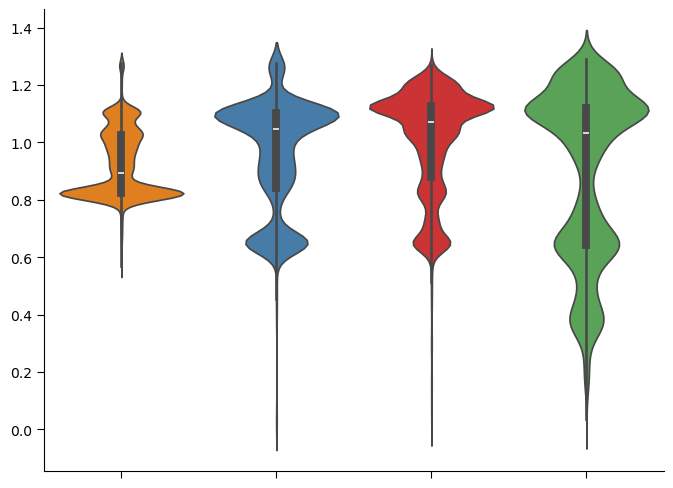

In [162]:
import seaborn as sns
import matplotlib.pyplot as plt

# Customize color palette (4 hex colors for the violins, you can adjust them)
custom_colors = ['#ff7f00', '#377eb8', '#e41a1c',  '#4daf4a']  # Example palette

# Create the figure and axes with the desired size
fig, ax = plt.subplots(figsize=(8, 6))  # Adjust figsize as needed

# Plot the violin plot with 'width' style and the custom color palette
sns.violinplot(data=organoids_purified.obs, 
               x='subtype_collapsed_annot_no_markers', 
               y='palantir_entropy', 
               palette=custom_colors, 
               ax=ax, 
               density_norm='width')   # Change violin style to 'width'

# Rotate x-axis labels by 30 degrees
plt.xticks(rotation=30)

# Remove x-axis labels but keep the ticks (the notches)
ax.set_xticklabels([])  # Remove x-axis labels (text)
ax.tick_params(axis='x', which='both', length=5)  # Keep x-axis ticks (notches)

# Optionally, remove y-axis labels and ticks
#ax.set_yticklabels([])  # Remove y-axis labels
ax.set_title('')  # Remove title
ax.set_xlabel('')  # Remove x-label
ax.set_ylabel('')  # Remove y-label
ax.tick_params(axis='y', which='both', length=5)  # Remove y-axis ticks if needed

# Optionally, save the figure
plt.savefig('/home/deepak/repositories/hippocampus/panels/palantir_entropy_violin_by_subtype_collapsed.svg', format='svg')

# Show the plot
plt.show()


(0.0, 0.5)

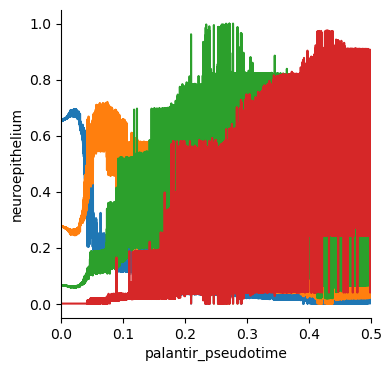

In [190]:
sns.lineplot(organoids_purified.obs, x='palantir_pseudotime', y='neuroepithelium')
sns.lineplot(organoids_purified.obs, x='palantir_pseudotime', y='mature_neuroepithelium')
sns.lineplot(organoids_purified.obs, x='palantir_pseudotime', y='radial_glia')
sns.lineplot(organoids_purified.obs, x='palantir_pseudotime', y='neuron')
plt.xlim(0,0.5)

/tmp/ipykernel_10992/4125049942.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_10992/4125049942.py:12: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



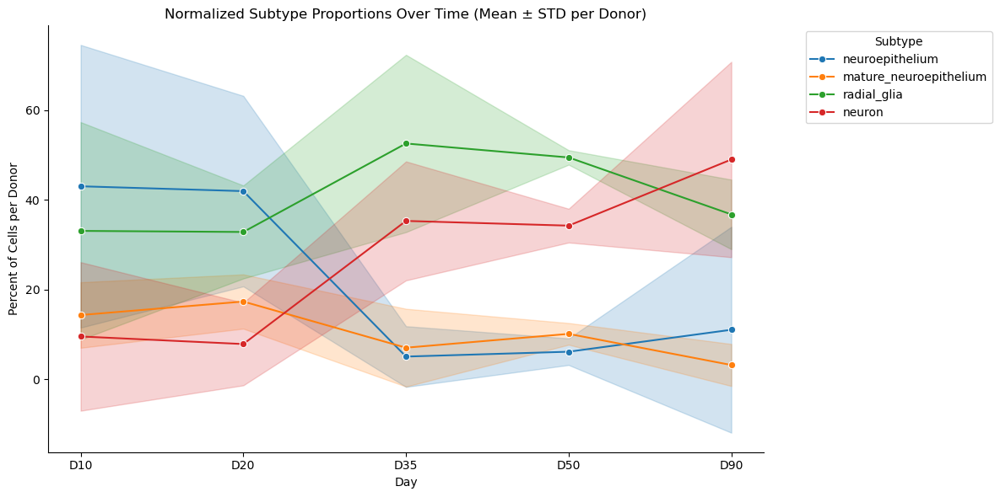

In [216]:
# Step 1: Count per donor-day-subtype
counts = (
    organoids_purified.obs
    .groupby(['Donor_ID', 'Day_condensed', 'subtype_collapsed_annot_no_markers'])
    .size()
    .reset_index(name='Count')
)

# Step 2: Total cells per donor per day
totals = (
    organoids_purified.obs
    .groupby(['Donor_ID', 'Day_condensed'])
    .size()
    .reset_index(name='Total')
)

# Step 3: Merge and compute percentage
df = counts.merge(totals, on=['Donor_ID', 'Day_condensed'])
df['Percent'] = df['Count'] / df['Total'] * 100

# Step 4: Rename for plotting
df.columns = ['Donor', 'Day', 'Subtype', 'Count', 'Total', 'Percent']

# Step 5: Order day
day_order = ['D10', 'D20', 'D35', 'D50', 'D90']
df['Day'] = pd.Categorical(df['Day'], categories=day_order, ordered=True)

# Step 6: Plot
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df,
    x='Day',
    y='Percent',
    hue='Subtype',
    estimator='mean',
    errorbar='sd',  # std dev across donors
    marker='o'
)

plt.title('Normalized Subtype Proportions Over Time (Mean ± STD per Donor)')
plt.ylabel('Percent of Cells per Donor')
plt.xlabel('Day')
plt.legend(title='Subtype', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('/home/deepak/repositories/hippocampus/panels/subtype_proportion_lineplot.svg', format='svg')
plt.show()


/tmp/ipykernel_10992/2102232498.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_10992/2102232498.py:12: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_10992/2102232498.py:30: FutureWarning:



The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.




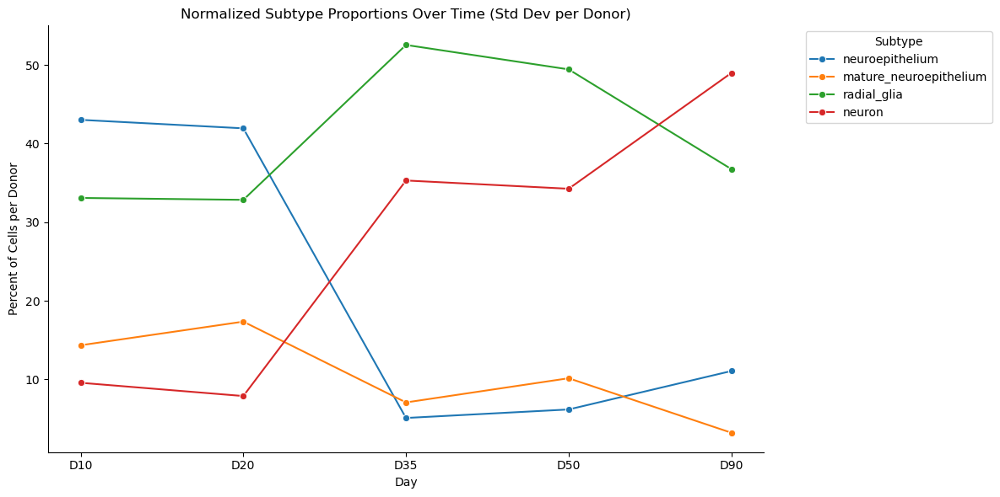

In [215]:
# Step 1: Count per donor-day-subtype
counts = (
    organoids_purified.obs
    .groupby(['Donor_ID', 'Day_condensed', 'subtype_collapsed_annot_no_markers'])
    .size()
    .reset_index(name='Count')
)

# Step 2: Total cells per donor per day
totals = (
    organoids_purified.obs
    .groupby(['Donor_ID', 'Day_condensed'])
    .size()
    .reset_index(name='Total')
)

# Step 3: Merge and compute percentage
df = counts.merge(totals, on=['Donor_ID', 'Day_condensed'])
df['Percent'] = df['Count'] / df['Total'] * 100

# Step 4: Rename for plotting
df.columns = ['Donor', 'Day', 'Subtype', 'Count', 'Total', 'Percent']

# Step 5: Order day
day_order = ['D10', 'D20', 'D35', 'D50', 'D90']
df['Day'] = pd.Categorical(df['Day'], categories=day_order, ordered=True)

# Step 6: Plot without averaging over donors
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df,
    x='Day',
    y='Percent',
    hue='Subtype',
    errorbar='sd',  # std dev across donors
    marker='o',
    ci=None  # Don't compute confidence intervals (you can add it if needed)
)

plt.title('Normalized Subtype Proportions Over Time (Std Dev per Donor)')
plt.ylabel('Percent of Cells per Donor')
plt.xlabel('Day')
plt.legend(title='Subtype', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


/tmp/ipykernel_10992/3304974857.py:8: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_10992/3304974857.py:16: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_10992/3304974857.py:33: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



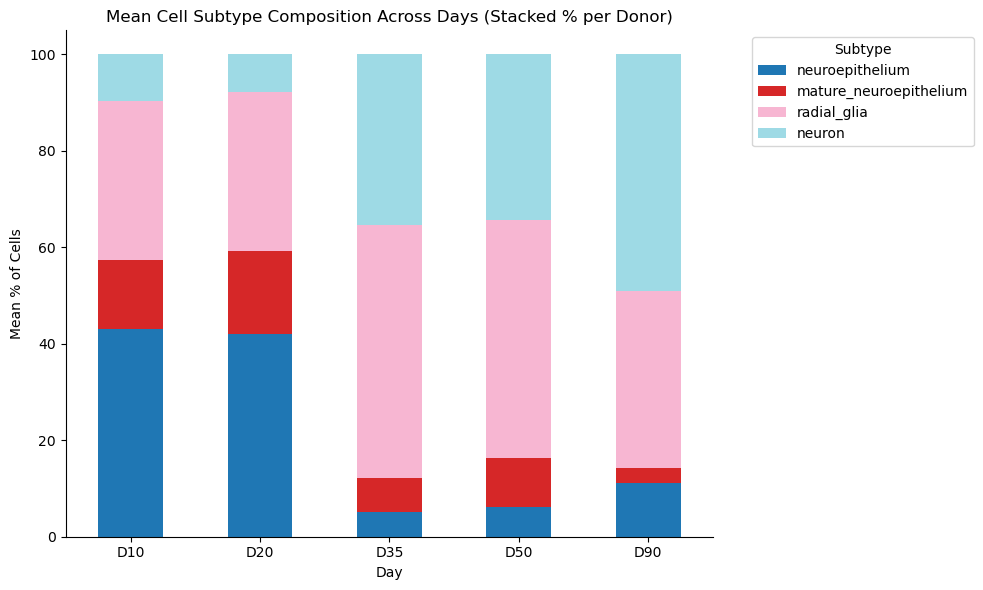

In [213]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Count cells per Donor-Day-Subtype
counts = (
    organoids_purified.obs
    .groupby(['Donor_ID', 'Day_condensed', 'subtype_collapsed_annot_no_markers'])
    .size()
    .reset_index(name='Count')
)

# Step 2: Total cells per Donor-Day
totals = (
    organoids_purified.obs
    .groupby(['Donor_ID', 'Day_condensed'])
    .size()
    .reset_index(name='Total')
)

# Step 3: Merge and compute Percent
df = counts.merge(totals, on=['Donor_ID', 'Day_condensed'])
df['Percent'] = df['Count'] / df['Total'] * 100

# Rename for clarity
df.columns = ['Donor', 'Day', 'Subtype', 'Count', 'Total', 'Percent']

# Step 4: Order the day axis
day_order = ['D10', 'D20', 'D35', 'D50', 'D90']
df['Day'] = pd.Categorical(df['Day'], categories=day_order, ordered=True)

# Step 5: Average across donors to get mean percentage per Day and Subtype
mean_perc = df.groupby(['Day', 'Subtype'])['Percent'].mean().reset_index()

# Step 6: Pivot for stacked barplot format
stacked_df = mean_perc.pivot(index='Day', columns='Subtype', values='Percent').fillna(0)

# Step 7: Plot
stacked_df.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='tab20'  # you can choose another like 'viridis' or 'Set3'
)

plt.title('Mean Cell Subtype Composition Across Days (Stacked % per Donor)')
plt.ylabel('Mean % of Cells')
plt.xlabel('Day')
plt.xticks(rotation=0)
plt.legend(title='Subtype', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
